In [1]:
import pandas as pd
import warnings
from matplotlib import pyplot as plt

warnings.filterwarnings('ignore')
df_feats = pd.read_csv('/home/sareeves/PSLMs/data/features/tsuboyama_all_subs_corrected_feats.csv', index_col=0)
df_feats['uid'] = df_feats['code'] + '_' + df_feats['mut_type']
df_feats = df_feats.set_index('uid')
df_feats.index = df_feats.index.str.replace('|', '_')

In [2]:
dfs = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/GB1_Wu_2016_binding_domain/esm3_forge/zero_shot/esm3-medium-2024-08/predictions_unmasked_singles.csv', index_col=0)
dfr = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/GB1_Wu_2016_binding_domain/esm3_forge/zero_shot/esm3-medium-2024-08/predictions_unmasked_old.csv', index_col=0)
dfr = dfr.loc[dfr['mut_type'].str.contains(':')]

dfn = pd.concat([dfs, dfr])
dfn.to_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/GB1_Wu_2016_binding_domain/esm3_forge/zero_shot/esm3-medium-2024-08/predictions_unmasked.csv')

In [3]:
df_feats.columns

Index(['aa_seq', 'mut_type', 'WT_name', 'code', 'pdb_file', 'mut_structure',
       'chain', 'ddG_ML', 'wild_type', 'position', 'mutation', 'msa_file',
       'reduced_msa_file', 'uniprot_seq', 'offset_up', 'on_interface',
       'entropy', 'conservation', 'column_completeness', 'completeness_score',
       'n_seqs', 'structure_length', 'features', 'hbonds', 'h_bond_ids',
       'saltbrs', 'b_factor', 'kdh_wt', 'kdh_mut', 'vol_wt', 'vol_mut',
       'chg_wt', 'chg_mut', 'sequence_length', 'SS', 'rel_ASA'],
      dtype='object')

In [24]:
dfs = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/SPURS/step_0-val_rho_avg_spearman_0.69_single_seed1.ckpt_single_predictions.csv', index_col=0).rename({'ddg_pred': 'SPURS'}, axis=1)
dft = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/thermompnnd/additive_single_hyperopt_splits_correct_bb_1_epoch=99_val_ddG_spearman=0.73.ckpt.csv', index_col=0).rename({'ddG_pred': 'ThermoMPNN'}, axis=1)
dfm = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/mutate_everything/af_single_hyperopt_splits_1_checkpoint-19.csv', index_col=0).rename({'ddg_pred': 'MutateEverything'}, axis=1)
dfe = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/msr_dual_ensemble_small_large/1/epoch=05-val_rho_combined_avg=0.805.ckpt_alpha16.0_predictions.csv', index_col=0).rename({'combined_pred': 'ESM-MSR'}, axis=1)
dfea20 = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/msr_dual_ensemble_small_large/1/epoch=05-val_rho_combined_avg=0.805.ckpt_alpha20.0_predictions.csv', index_col=0).rename({'combined_pred': 'ESM-MSR (σ=1.25)'}, axis=1)
dfea8 = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/msr_dual_ensemble_small_large/1/epoch=05-val_rho_combined_avg=0.805.ckpt_alpha8.0_predictions.csv', index_col=0).rename({'combined_pred': 'ESM-MSR (σ=0.5)'}, axis=1)
dfe3 = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/msr_masked_chain/1/epoch=04-val_rho_avg=0.815.ckpt_alpha16chain_rule_avg_masked.csv', index_col=0).rename({'ddg_pred': 'ESM-MSR_masked'}, axis=1)
dfp = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/proteinmpnn/proteinmpnn_020_unmasked.csv', index_col=8).rename({'mpnn_score': 'ProteinMPNN'}, axis=1)

df_zero_sm_op = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/zeroshot_alpha0_predictions.csv', index_col=0).rename({'combined_pred': 'ESM3-small-open'}, axis=1)
df_zero_sm_masked_op = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/None_alpha0chain_rule_avg_masked.csv', index_col=0).rename({'ddg_pred': 'ESM3-small-open_masked'}, axis=1)

df_zero_sm = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/esm3_forge/zero_shot/esm3-small-2024-08/predictions_unmasked.csv', index_col=0).rename({'esm3_score': 'ESM3-small'}, axis=1)
df_zero_med = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/esm3_forge/zero_shot/esm3-medium-2024-08/predictions_unmasked.csv', index_col=0).rename({'esm3_score': 'ESM3-medium'}, axis=1)

#df_zero_sm = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/zero_shot/esm3-small-2024-08_masked.csv', index_col=0).rename({'esm3_score': 'esm3-small'}, axis=1)
#df_zero_med = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/zero_shot/esm3-medium-2024-08_masked.csv', index_col=0).rename({'esm3_score': 'esm3-medium'}, axis=1)
#df_zero_lg = pd.read_csv(f'/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/zero_shot/esm3-large-2024-03_masked.csv', index_col=0).rename({'esm3_score': 'esm3-large'}, axis=1)
#dfr = pd.read_csv('./predictions_good_may9/rosetta_all_preds_april17.csv', index_col=0).rename({'cartesian_ddg_dir': 'cartesian_ddg'}, axis=1)
dfr1 = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/rosetta/cartesian_ddg.csv', index_col=0).dropna(how='all', axis=1).rename({'cartesian_ddg_1': 'Rosetta Cartesian DDG'}, axis=1)
#dfr2 = pd.read_csv('./predictions_good_may9/rosetta_all_preds_april17.csv', index_col=0).rename({'cartesian_ddg_dir': 'cartesian_ddg'}, axis=1)

dfe.index = dfe.index.str.replace('|', '_')
print(len(dfe.loc[~dfe['mut_type'].str.contains(':')]), len(dfm.loc[~dfm['mut_type'].str.contains(':')]), len(dft))

32968 32968 43700


10732 32968


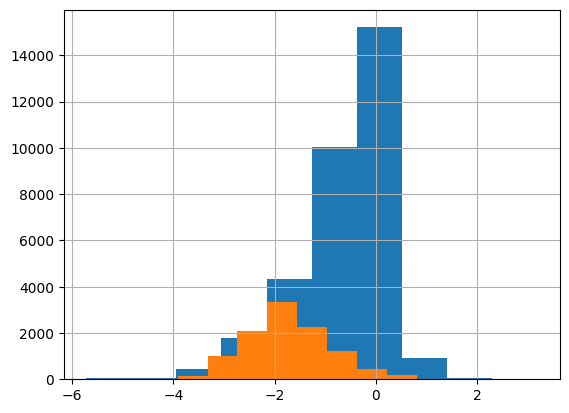

In [26]:
df_preds = dfe.join(dfea20['ESM-MSR (σ=1.25)']).join(dfea8['ESM-MSR (σ=0.5)']).join(dfe3['ESM-MSR_masked']).join(dfm[['MutateEverything']]).join(dfs[['SPURS']]).join(dft[['ThermoMPNN']]).join(dfp[['ProteinMPNN']]).join(dfr1[['Rosetta Cartesian DDG']]).join(df_zero_sm_op[['ESM3-small-open']]).join(df_zero_med[['ESM3-medium']]) #.join(df_zero_med[['esm3-medium']]).join(df_zero_lg[['esm3-large']]) #.join(dfr2[['cartesian_ddg']])
df_preds.loc[~df_preds['mut_type'].str.contains(':'), 'ddG_ML'].hist()
df_preds.loc[df_preds['mut_type'].str.contains(':'), 'ddG_ML'].hist()
print(len(df_preds.loc[df_preds['mut_type'].str.contains(':'), 'ddG_ML']), len(df_preds.loc[~df_preds['mut_type'].str.contains(':'), 'ddG_ML']))

In [27]:
df_preds_singles = df_preds.loc[~df_preds['mut_type'].str.contains(':')]
assert len(df_preds_singles[df_preds_singles[['ThermoMPNN', 'MutateEverything', 'ESM-MSR', 'SPURS']].isna().any(axis=1)]) == 0

In [28]:
#df_preds = df_preds.dropna().loc[~df_preds.dropna()['mut_type'].str.contains(':')]
db_complete = df_preds_singles.join(df_feats.drop([c for c in df_feats.columns if c in df_preds.columns], axis=1))
db_complete

,aa_seq,mut_type,WT_name,mut_structure,code_wt,code,chain,uid,ddG_ML,pdb_file,...,b_factor,kdh_wt,kdh_mut,vol_wt,vol_mut,chg_wt,chg_mut,sequence_length,SS,rel_ASA
id,,,,,,,,,,,,,,,,,,,,,
1UFM_A11C,SSGGSSILDRCVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11C,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11C,0.004061,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.5,1.00,2.43,0,0,72,H,0.500000
1UFM_A11D,SSGGSSILDRDVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11D,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11D,-0.023454,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,2.78,0,-1,72,H,0.500000
1UFM_A11E,SSGGSSILDREVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11E,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11E,0.111864,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,3.78,0,-1,72,H,0.500000
1UFM_A11F,SSGGSSILDRFVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11F,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11F,-0.153650,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.8,1.00,5.89,0,0,72,H,0.500000
1UFM_A11G,SSGGSSILDRGVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11G,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11G,-0.393182,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-0.4,1.00,0.00,0,0,72,H,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_Y41R,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKRPNLKVELE,Y41R,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41R,-1.057192,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-4.5,6.47,6.13,0,1,49,-,0.418919
r11_233_TrROS_Hall_Y41S,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKSPNLKVELE,Y41S,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41S,-1.259837,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-0.8,6.47,1.60,0,0,49,-,0.418919
r11_233_TrROS_Hall_Y41T,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKTPNLKVELE,Y41T,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41T,-1.280677,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-0.7,6.47,2.60,0,0,49,-,0.418919


In [29]:
df_feats_no_destab = df_feats.loc[df_feats['mut_structure'].isna()]
db_complete_no_destab = df_preds_singles.join(df_feats_no_destab.drop([c for c in df_feats.columns if c in df_preds.columns], axis=1), how='inner')
db_complete_no_destab 

,aa_seq,mut_type,WT_name,mut_structure,code_wt,code,chain,uid,ddG_ML,pdb_file,...,b_factor,kdh_wt,kdh_mut,vol_wt,vol_mut,chg_wt,chg_mut,sequence_length,SS,rel_ASA
1UFM_A11C,SSGGSSILDRCVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11C,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11C,0.004061,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.5,1.00,2.43,0,0,72,H,0.500000
1UFM_A11D,SSGGSSILDRDVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11D,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11D,-0.023454,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,2.78,0,-1,72,H,0.500000
1UFM_A11E,SSGGSSILDREVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11E,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11E,0.111864,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,3.78,0,-1,72,H,0.500000
1UFM_A11F,SSGGSSILDRFVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11F,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11F,-0.153650,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.8,1.00,5.89,0,0,72,H,0.500000
1UFM_A11G,SSGGSSILDRGVIEHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,A11G,1UFM.pdb,-,1UFM,1UFM,A,1UFM_A11G,-0.393182,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-0.4,1.00,0.00,0,0,72,H,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_Y41R,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKRPNLKVELE,Y41R,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41R,-1.057192,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-4.5,6.47,6.13,0,1,49,-,0.418919
r11_233_TrROS_Hall_Y41S,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKSPNLKVELE,Y41S,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41S,-1.259837,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-0.8,6.47,1.60,0,0,49,-,0.418919
r11_233_TrROS_Hall_Y41T,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKTPNLKVELE,Y41T,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41T,-1.280677,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,-0.7,6.47,2.60,0,0,49,-,0.418919
r11_233_TrROS_Hall_Y41V,KTYTFRVRIVDEETGEEKEIEVTAKSEEEAKKAAEELKKKVPNLKVELE,Y41V,r11_233_TrROS_Hall.pdb,-,r11_233_TrROS_Hall,r11_233_TrROS_Hall,A,r11_233_TrROS_Hall_Y41V,-1.305513,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-1.3,4.2,6.47,3.00,0,0,49,-,0.418919


In [30]:
df_feats_destab = df_feats.loc[~df_feats['mut_structure'].isna()]
db_complete_destab = df_preds_singles.join(df_feats_destab.drop([c for c in df_feats.columns if c in df_preds.columns], axis=1), how='inner')
db_complete_destab 

,aa_seq,mut_type,WT_name,mut_structure,code_wt,code,chain,uid,ddG_ML,pdb_file,...,b_factor,kdh_wt,kdh_mut,vol_wt,vol_mut,chg_wt,chg_mut,sequence_length,SS,rel_ASA
2K5H_G11S_A16C,AVSDRLIGRKSVVMECISPQNSGLVKVDGETWRATSGTVLDVGEEV...,A16C,2K5H.pdb_G11S,G11S,2K5H,2K5H_G11S,A,2K5H_G11S_A16C,-0.213358,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.5,1.00,2.43,0,0,62,-,0.490566
2K5H_G11S_A16D,AVSDRLIGRKSVVMEDISPQNSGLVKVDGETWRATSGTVLDVGEEV...,A16D,2K5H.pdb_G11S,G11S,2K5H,2K5H_G11S,A,2K5H_G11S_A16D,-2.029711,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,2.78,0,-1,62,-,0.490566
2K5H_G11S_A16E,AVSDRLIGRKSVVMEEISPQNSGLVKVDGETWRATSGTVLDVGEEV...,A16E,2K5H.pdb_G11S,G11S,2K5H,2K5H_G11S,A,2K5H_G11S_A16E,-1.146346,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-3.5,1.00,3.78,0,-1,62,-,0.490566
2K5H_G11S_A16F,AVSDRLIGRKSVVMEFISPQNSGLVKVDGETWRATSGTVLDVGEEV...,A16F,2K5H.pdb_G11S,G11S,2K5H,2K5H_G11S,A,2K5H_G11S_A16F,-0.681503,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,2.8,1.00,5.89,0,0,62,-,0.490566
2K5H_G11S_A16G,AVSDRLIGRKSVVMEGISPQNSGLVKVDGETWRATSGTVLDVGEEV...,A16G,2K5H.pdb_G11S,G11S,2K5H,2K5H_G11S,A,2K5H_G11S_A16G,-0.894964,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,1.8,-0.4,1.00,0.00,0,0,62,-,0.490566
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2K5H_G23A_W32I,AVSDRLIGRKGVVMEAISPQNSALVKVDGETIRATSGTVLDVGEEV...,W32I,2K5H.pdb_G23A,G23A,2K5H,2K5H_G23A,A,2K5H_G23A_W32I,-2.467404,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-0.9,4.5,8.08,4.00,0,0,62,E,0.387665
2K5H_G23A_W32L,AVSDRLIGRKGVVMEAISPQNSALVKVDGETLRATSGTVLDVGEEV...,W32L,2K5H.pdb_G23A,G23A,2K5H,2K5H_G23A,A,2K5H_G23A_W32L,-1.535847,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-0.9,3.8,8.08,4.00,0,0,62,E,0.387665
2K5H_G23A_W32M,AVSDRLIGRKGVVMEAISPQNSALVKVDGETMRATSGTVLDVGEEV...,W32M,2K5H.pdb_G23A,G23A,2K5H,2K5H_G23A,A,2K5H_G23A_W32M,-1.658541,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-0.9,1.9,8.08,4.43,0,0,62,E,0.387665
2K5H_G23A_W32R,AVSDRLIGRKGVVMEAISPQNSALVKVDGETRRATSGTVLDVGEEV...,W32R,2K5H.pdb_G23A,G23A,2K5H,2K5H_G23A,A,2K5H_G23A_W32R,-2.273516,/home/sareeves/software/esm-msr/data/tsuboyama...,...,NaN,-0.9,-4.5,8.08,6.13,0,1,62,E,0.387665


In [31]:
db_complete['ddG'] = db_complete['ddG_ML']
db_complete['delta_vol'] = db_complete['vol_mut'] - db_complete['vol_wt']
db_complete['delta_kdh'] = db_complete['kdh_mut'] - db_complete['kdh_wt']
db_complete['upper_bound'] = db_complete['ddG']

In [32]:
db_complete_no_destab['ddG'] = db_complete_no_destab['ddG_ML']
db_complete_no_destab['delta_vol'] = db_complete_no_destab['vol_mut'] - db_complete_no_destab['vol_wt']
db_complete_no_destab['delta_kdh'] = db_complete_no_destab['kdh_mut'] - db_complete_no_destab['kdh_wt']
db_complete_no_destab['upper_bound'] = db_complete_no_destab['ddG']

In [33]:
db_complete_destab['ddG'] = db_complete_destab['ddG_ML']
db_complete_destab['delta_vol'] = db_complete_destab['vol_mut'] - db_complete_destab['vol_wt']
db_complete_destab['delta_kdh'] = db_complete_destab['kdh_mut'] - db_complete_destab['kdh_wt']
db_complete_destab['upper_bound'] = db_complete_destab['ddG']

In [34]:
import pandas as pd
import numpy as np

def percentile_by_group(df, group_col, score_col, threshold=0.9):
    """
    Converts scores to percentiles within each group in a DataFrame
    and adds a column with original scores above a given percentile threshold.

    Args:
        df (pd.DataFrame): The input DataFrame.
        group_col (str): The name of the column to group by.
        score_col (str): The name of the column containing scores.
        threshold (float): The percentile threshold (0.0 to 1.0).
                           Scores with percentiles above this threshold will be kept.

    Returns:
        pd.DataFrame: The DataFrame with added columns for percentile scores
                      and scores above the threshold.
    """
    percentile_col_name = f'percentile_{score_col}'
    # Group by the specified column and calculate percentiles
    df[percentile_col_name] = df.groupby(group_col)[score_col].transform(
        lambda x: x.rank(method='max', pct=True)
    )

    # Print the min and max percentiles
    min_percentile = df[percentile_col_name].min()
    max_percentile = df[percentile_col_name].max()

    print(f"Minimum percentile for '{score_col}': {min_percentile}")
    print(f"Maximum percentile for '{score_col}': {max_percentile}")

    # Add a new column for scores above the threshold
    threshold_col_name = f'{score_col}_above_{int(threshold*100)}th_percentile'
    df[threshold_col_name] = np.where(
        df[percentile_col_name] > threshold, # Condition: percentile is greater than threshold
        df[score_col],                      # Value if True: original score
        np.nan                              # Value if False: NaN
    )

    return df

def topk_by_group(df, group_col, score_col, ground_truth_col, threshold=None, set_k=None):
    """
    Filter scores to only include top-k values per group, where k is determined
    by the number of ground truth values above threshold in each group.
    
    Parameters:
    -----------
    df : DataFrame
        Input dataframe
    group_col : str
        Column name to group by
    score_col : str
        Column name containing scores to rank
    ground_truth_col : str
        Column name containing ground truth values to determine k
    threshold : float
        Threshold for ground truth values (default: 0.5)
    
    Returns:
    --------
    DataFrame with additional columns:
        - rank_{score_col}: rank of scores within each group
        - k_per_group: number of ground truth values > threshold per group
        - is_topk_{score_col}: boolean indicating if score is in top-k
        - {score_col}_in_topk: original score if in top-k, else NaN
    """

    assert not ((threshold is not None) and (set_k is not None))
    if threshold is not None:
        name = threshold
    elif set_k is not None:
        name = set_k
    else:
        assert False
    
    # Create a copy to avoid modifying the original
    df = df.copy()
    
    # Calculate ranks within each group (higher scores get lower ranks)
    rank_col_name = f'rank_{score_col}'
    df[rank_col_name] = df.groupby(group_col)[score_col].transform(
        lambda x: x.rank(method='first', ascending=False)
    )
    
    if set_k is None:
        # Calculate k for each group (number of ground truth values > threshold)
        k_per_group = df.groupby(group_col)[ground_truth_col].transform(
            lambda x: (x > threshold).sum()
        )
        df['k_per_group'] = k_per_group
    else:
        df['k_per_group'] = set_k

    # Determine which scores are in top-k for their group
    is_topk_col_name = f'is_topk{set_k if set_k else ""}_{score_col}{("_"+threshold) if threshold else ""}'
    df[is_topk_col_name] = df[rank_col_name] <= df['k_per_group']
    
    # Add a new column for scores in top-k (NaN otherwise)
    threshold_col_name = f'{score_col}_in_topk{set_k if set_k else ""}{("_"+threshold) if threshold else ""}'
    df[threshold_col_name] = np.where(
        df[is_topk_col_name],
        df[score_col],
        np.nan
    )
    
    return df

db_complete['upper_bound'] = db_complete['ddG']

In [35]:
def plot_aa_preference_and_gain(df, models, aa_col='mutated_aa', ddg_col='ddG', 
                                layout='side-by-side', figsize=(12, 6),
                                title_ax1=None,
                                title_ax2=None,
                                ylabel_ax1='Rectified total gain (kcal/mol)', ylabel_ax2='Mutation Count',
                                k=96):
    """
    Creates a two-panel stacked barplot.
    Bottom/Right panel: Amino acid counts for top-k mutations per model.
    Top/Left panel: Sum of ddG values for top-k mutations per model.
    
    Args:
        df (pd.DataFrame): Input dataframe.
        models (list of str): List of model names.
        aa_col (str): Column name containing the mutated amino acid.
        ddg_col (str): Column name containing the ddG scores.
        layout (str): 'stacked' (vertical) or 'side-by-side' (horizontal).
        figsize (tuple): Dimensions of the figure.
        title_ax1 (str): Title for the ddG plot.
        title_ax2 (str): Title for the counts plot.
        ylabel_ax1 (str): Y-axis label for the ddG plot. Defaults to 'Sum of {ddg_col}'.
        ylabel_ax2 (str): Y-axis label for the counts plot.
    """
    
    # 1. Validation Checks
    assert isinstance(df, pd.DataFrame), "Input df must be a pandas DataFrame."
    assert aa_col in df.columns, f"Amino acid column '{aa_col}' not found in DataFrame."
    assert ddg_col in df.columns, f"ddG column '{ddg_col}' not found in DataFrame."
    assert layout in ['stacked', 'side-by-side'], f"Invalid layout '{layout}'. Must be 'stacked' or 'side-by-side'."
    
    for model in models:
        col_name = f"is_topk{k}_{model}"
        assert col_name in df.columns, f"Expected boolean column '{col_name}' not found."
        assert pd.api.types.is_bool_dtype(df[col_name]) or set(df[col_name].dropna().unique()).issubset({0, 1}), \
            f"Column '{col_name}' must be boolean or binary (0/1)."

    # 2. Define Amino Acid Categories and Colors
    # C is explicitly extracted to the front for bottom-stacking/top-legend positioning
    ordered_aas = ['C']
    aa_colors = {'C': '#FFD700'}  # Special color: Gold/Yellow
    
    categories = {
        'Hydrophobic': (['A', 'V', 'L', 'I', 'M', 'F', 'W', 'P', 'G'], plt.cm.Blues),
        'Polar':       (['S', 'T', 'Y', 'N', 'Q'], plt.cm.Greens), # 'C' removed from here
        'Positive':    (['R', 'H', 'K'], plt.cm.Reds),
        'Negative':    (['D', 'E'], plt.cm.Purples)
    }
    
    # Generate distinct shades for each AA within its category's base colormap
    for cat, (aas, cmap) in categories.items():
        ordered_aas.extend(aas)
        colors = cmap(np.linspace(0.35, 0.9, len(aas)))
        for aa, color in zip(aas, colors):
            aa_colors[aa] = color
            
    # 3. Aggregate Data
    counts_data = {model: {aa: 0 for aa in ordered_aas} for model in models}
    ddg_data = {model: {aa: 0.0 for aa in ordered_aas} for model in models}
    
    for model in models:
        col_name = f"is_topk{k}_{model}"
        mask = df[col_name] == True
        filtered_df = df[mask]
        
        counts = filtered_df[aa_col].value_counts()
        sums = filtered_df.groupby(aa_col)[ddg_col].sum()
        
        for aa in ordered_aas:
            counts_data[model][aa] = counts.get(aa, 0)
            ddg_data[model][aa] = sums.get(aa, 0.0)
            
    # Calculate thresholds for text insertion (roughly 3% of the max stack height)
    try:
        max_count = max(sum(counts_data[m].values()) for m in models)
        threshold_count = max_count * 0.03
    except ValueError:
        threshold_count = 0
        
    try:
        max_ddg = max(sum(abs(v) for v in ddg_data[m].values()) for m in models)
        threshold_ddg = max_ddg * 0.03
    except ValueError:
        threshold_ddg = 0

    # 4. Plotting
    if layout == 'stacked':
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize, sharex=True)
    else:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, sharex=False)
        
    x = np.arange(len(models))
    
    # TOP/LEFT PLOT: Sum of ddG
    bottom_ddg_pos = np.zeros(len(models))
    bottom_ddg_neg = np.zeros(len(models))
    
    for aa in ordered_aas:
        y_vals = np.array([ddg_data[m][aa] for m in models])
        
        if (y_vals < 0).any() and (y_vals > 0).any():
            print(f"WARNING: Amino acid '{aa}' has both positive and negative ddG sums. "
                  f"Stacking mixed signs is visually problematic and text labels may overlap.")
            
        y_bases = np.where(y_vals >= 0, bottom_ddg_pos, bottom_ddg_neg)
        ax1.bar(x, y_vals, bottom=y_bases, color=aa_colors[aa], edgecolor='white', linewidth=0.5)
        
        # Insert text if there is space
        for i, y in enumerate(y_vals):
            if abs(y) > threshold_ddg:
                y_center = y_bases[i] + (y / 2)
                ax1.text(x[i], y_center, aa, ha='center', va='center', color='black', fontsize=8, fontweight='bold')
        
        bottom_ddg_pos += np.where(y_vals >= 0, y_vals, 0)
        bottom_ddg_neg += np.where(y_vals < 0, y_vals, 0)
        
    ax1.set_ylabel(ylabel_ax1 if ylabel_ax1 is not None else f'Sum of {ddg_col}')
    ax1.set_title(title_ax1)
    ax1.axhline(0, color='black', linewidth=1) # baseline
    
    # BOTTOM/RIGHT PLOT: AA Counts
    bottom_counts = np.zeros(len(models))
    for aa in ordered_aas:
        y_vals = np.array([counts_data[m][aa] for m in models])
        ax2.bar(x, y_vals, bottom=bottom_counts, color=aa_colors[aa], label=aa, 
                edgecolor='white', linewidth=0.5)
        
        # Insert text if there is space
        for i, y in enumerate(y_vals):
            if y > threshold_count:
                y_center = bottom_counts[i] + (y / 2)
                ax2.text(x[i], y_center, aa, ha='center', va='center', color='black', fontsize=8, fontweight='bold')
                
        bottom_counts += y_vals
        
    ax2.set_ylabel(ylabel_ax2)
    ax2.set_title(title_ax2)
    
    # Formatting
    ax2.set_xticks(x)
    ax2.set_xticklabels(models, rotation=45, ha='right')
    
    # Apply x-ticks to ax1 if side-by-side or not sharing axes
    if layout == 'side-by-side':
        ax1.set_xticks(x)
        ax1.set_xticklabels(models, rotation=45, ha='right')
    
    # Legend handling
    handles = [plt.Rectangle((0,0),1,1, color=aa_colors[aa]) for aa in ordered_aas]
    
    # Reverse legend order and inset into the top/left panel
    ax1.legend(handles[::-1], ordered_aas[::-1], loc='upper right', 
               title="Amino Acids", ncol=4)
    
    plt.tight_layout()
    return fig, (ax1, ax2)

In [41]:
subset = ['upper_bound', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Rosetta Cartesian DDG', 'ddG'] #'esm3-small', 'esm3-medium', 'esm3-large',

(<Figure size 1200x600 with 2 Axes>,
 (<Axes: ylabel='Rectified total gain (kcal/mol)'>,
  <Axes: ylabel='Mutation Count'>))

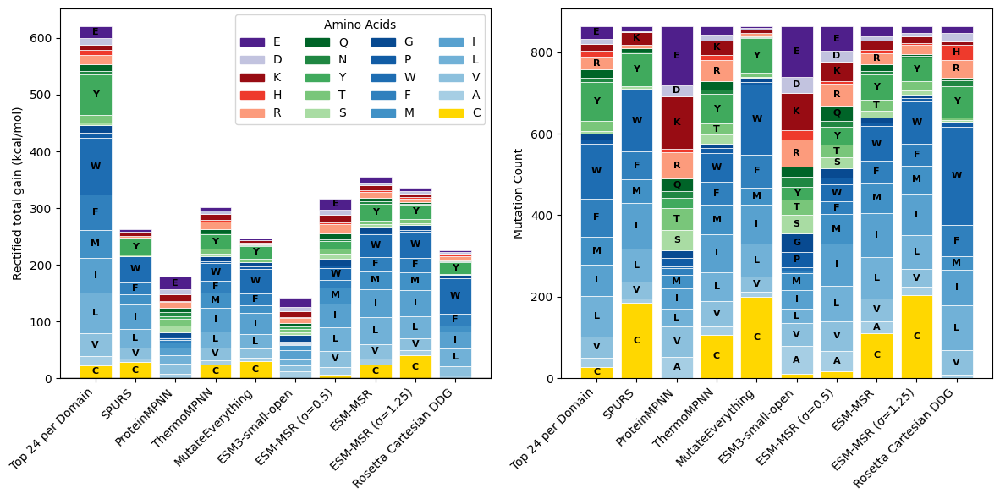

In [43]:
db_fig = db_complete[[c for c in db_complete if c in subset or c == 'code']]
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=24)
#db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR_masked', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=24)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0
db_fig['mutated_aa'] = db_fig.index.str[-1]
db_fig = db_fig.rename(columns={'upper_bound_in_topk_24': 'Top 24 per Domain',
                                'is_topk24_upper_bound': 'is_topk24_Top 24 per Domain'})

plot_aa_preference_and_gain(db_fig, models=['Top 24 per Domain'] + subset[1:-1], k=24)

(<Figure size 1200x600 with 2 Axes>,
 (<Axes: ylabel='Rectified total gain (kcal/mol)'>,
  <Axes: ylabel='Mutation Count'>))

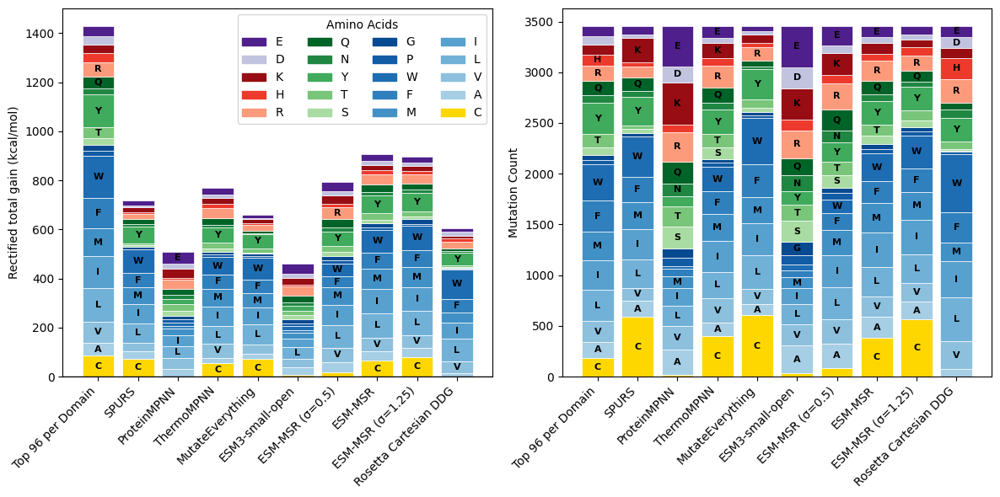

In [44]:
db_fig = db_complete[[c for c in db_complete if c in subset or c == 'code']]
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=96)
#db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR_masked', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=96)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0
db_fig['mutated_aa'] = db_fig.index.str[-1]
db_fig = db_fig.rename(columns={'is_topk96_upper_bound': 'is_topk96_Top 96 per Domain'})

plot_aa_preference_and_gain(db_fig, models=['Top 96 per Domain'] + subset[1:-1])

In [21]:
db_fig['is_topk96_ESM-MSR (σ=0.5)']

id
1UFM_A11C                  False
1UFM_A11D                  False
1UFM_A11E                  False
1UFM_A11F                  False
1UFM_A11G                  False
                           ...  
r11_233_TrROS_Hall_Y41R    False
r11_233_TrROS_Hall_Y41S    False
r11_233_TrROS_Hall_Y41T    False
r11_233_TrROS_Hall_Y41V    False
r11_233_TrROS_Hall_Y41W    False
Name: is_topk96_ESM-MSR (σ=0.5), Length: 32968, dtype: bool

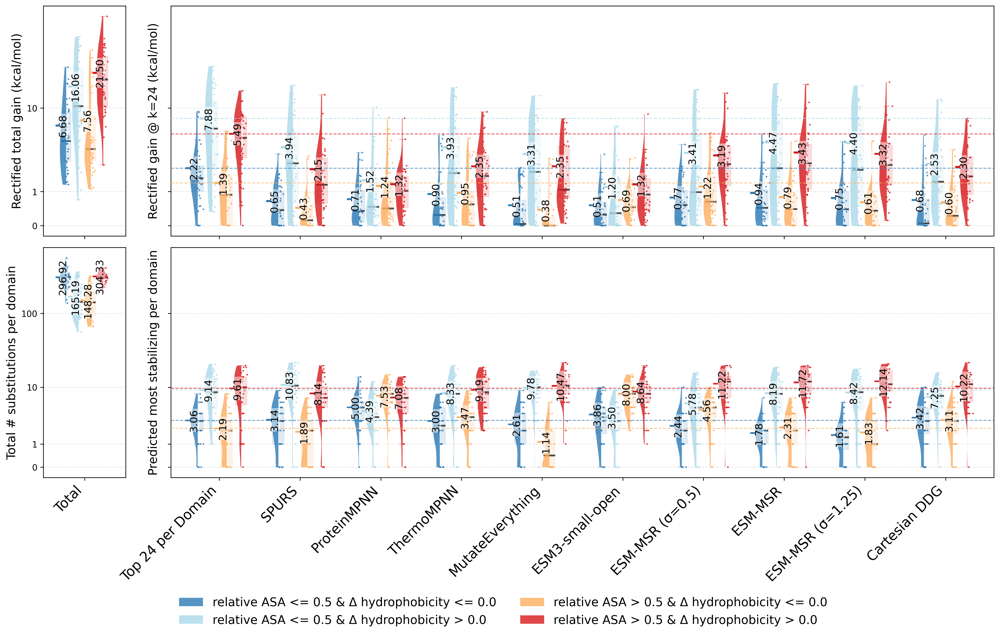

In [45]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

current_feats = ['delta_kdh', 'rel_ASA', 'ddG']

db_fig = db_complete[[c for c in db_complete if c in subset or c in current_feats or c == 'code']].dropna(subset=current_feats)
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=24)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=24)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0

db_fig = db_fig.drop(subset[:-1], axis=1)
db_fig = db_fig.rename({'upper_bound_in_topk24': 'Top 24 per Domain',
                        'ProteinMPNN_in_topk24': 'ProteinMPNN',
                        'ThermoMPNN_in_topk24': 'ThermoMPNN',
                        'MutateEverything_in_topk24': 'MutateEverything', 
                        'ESM3-small-open_in_topk24': 'ESM3-small-open',
                        'ESM-MSR_in_topk24': 'ESM-MSR',
                        'ESM-MSR (σ=0.5)_in_topk24': 'ESM-MSR (σ=0.5)',
                        'ESM-MSR (σ=1.25)_in_topk24': 'ESM-MSR (σ=1.25)',
                        'SPURS_in_topk24': 'SPURS',
                        'Rosetta Cartesian DDG_in_topk24': 'Cartesian DDG',
                        'delta_kdh': 'Δ hydrophobicity', 
                        'delta_vol': 'Δ volume', 
                        'rel_ASA': 'relative ASA', 
                        'neff': 'N eff. seqs'}, axis=1)

db_fig['Total'] = db_fig['ddG']

d, models, fig = analysis_utils_msr.compare_performance_per_group(
                        db_fig,
                        split_col = 'relative ASA',
                        split_col_2 = 'Δ hydrophobicity',
                        threshold_1 = 0.5, 
                        threshold_2 = 0., 
                        measurement = 'ddG',
                        statistic = 'net_stabilization',
                        #statistic_2 = 'weighted_spearman',
                        #n_bootstraps = 10,
                        #count_muts = True,
                        subset=['Total', 'Top 24 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG', 'ddG'],
                        grouper='code',
                        order=['Total', 'Top 24 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG'],
                        #plots='top',
                        drop_label = True,
                        split_last = True,
                        legend_loc = 'below',
                        #saveloc_perf = 'tmp.csv',
                        #show_boxes = True,
                        figsize = (20,10),
                        #annotation_position = 'above',
                        orientation='vertical',
                        #alt_stat_name='Rectified gain @ k=24',
                        #duplicates=True,
                        split_left_model=True,
                        left_group_label = 'Rectified total gain (kcal/mol)',
                        right_group_label = 'Rectified gain @ k=24 (kcal/mol)',
                        # scaffold order is col1 & col2 > T, col1 < T & col2 > T, col1 > T and col2 < T, col1 & col2 < T
                        )

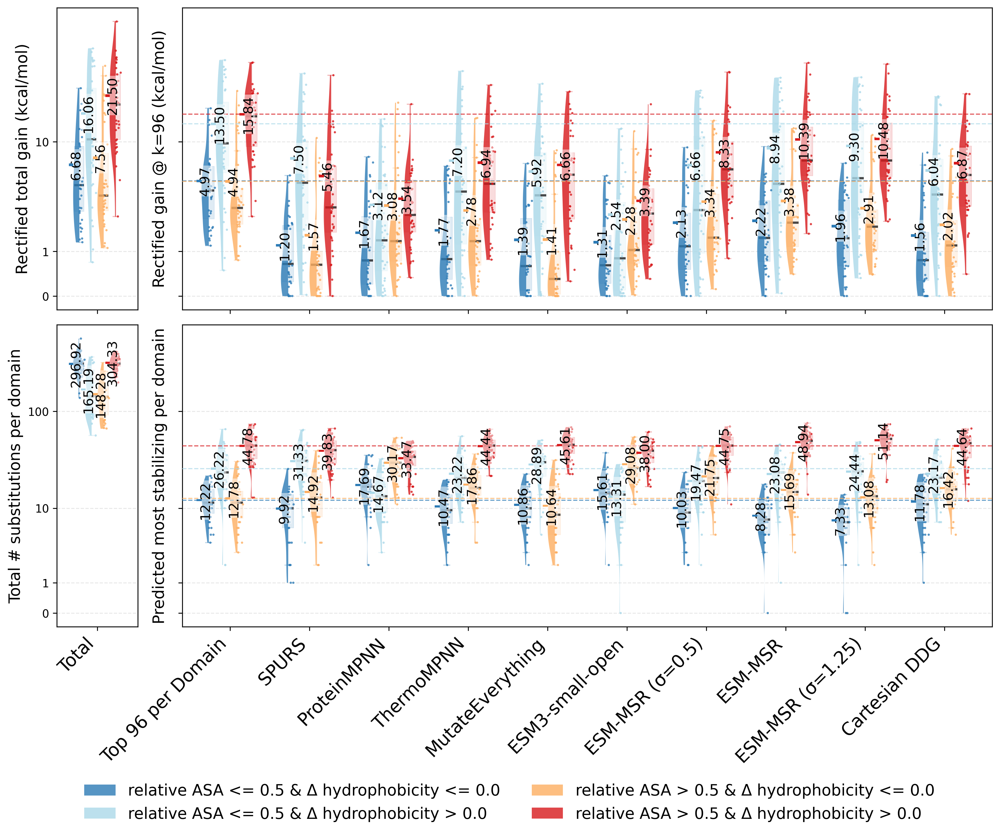

In [48]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

current_feats = ['delta_kdh', 'rel_ASA', 'ddG']

db_fig = db_complete[[c for c in db_complete if c in subset or c in current_feats or c == 'code']].dropna(subset=current_feats)
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=96)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0

db_fig = db_fig.drop(subset[:-1], axis=1)
db_fig = db_fig.rename({'upper_bound_in_topk96': 'Top 96 per Domain',
                        'ProteinMPNN_in_topk96': 'ProteinMPNN',
                        'ThermoMPNN_in_topk96': 'ThermoMPNN',
                        'MutateEverything_in_topk96': 'MutateEverything', 
                        'ESM3-small-open_in_topk96': 'ESM3-small-open',
                        'ESM-MSR_in_topk96': 'ESM-MSR',
                        'ESM-MSR (σ=0.5)_in_topk96': 'ESM-MSR (σ=0.5)',
                        'ESM-MSR (σ=1.25)_in_topk96': 'ESM-MSR (σ=1.25)',
                        'SPURS_in_topk96': 'SPURS',
                        'Rosetta Cartesian DDG_in_topk96': 'Cartesian DDG',
                        'delta_kdh': 'Δ hydrophobicity', 
                        'delta_vol': 'Δ volume', 
                        'rel_ASA': 'relative ASA', 
                        'neff': 'N eff. seqs'}, axis=1)

db_fig['Total'] = db_fig['ddG']

d, models, fig = analysis_utils_msr.compare_performance_per_group(
                        db_fig,
                        split_col = 'relative ASA',
                        split_col_2 = 'Δ hydrophobicity',
                        threshold_1 = 0.5, 
                        threshold_2 = 0., 
                        measurement = 'ddG',
                        statistic = 'net_stabilization',
                        #statistic_2 = 'weighted_spearman',
                        #n_bootstraps = 10,
                        #count_muts = True,
                        subset=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG', 'ddG'],
                        grouper='code',
                        order=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG'],
                        #plots='top',
                        drop_label = True,
                        split_last = True,
                        legend_loc = 'below',
                        #saveloc_perf = 'tmp.csv',
                        #show_boxes = True,
                        figsize = (15,10),
                        #annotation_position = 'above',
                        orientation='vertical',
                        #alt_stat_name='Rectified gain @ k=96',
                        #duplicates=True,
                        split_left_model=True,
                        left_group_label = 'Rectified total gain (kcal/mol)',
                        right_group_label = 'Rectified gain @ k=96 (kcal/mol)',
                        # scaffold order is col1 & col2 > T, col1 < T & col2 > T, col1 > T and col2 < T, col1 & col2 < T
                        )

In [49]:
db_fig.iloc[:, :20]

,code,relative ASA,ddG,Δ hydrophobicity,rank_ESM3-small-open,k_per_group,is_topk96_ESM3-small-open,ESM3-small-open,rank_ESM-MSR (σ=0.5),is_topk96_ESM-MSR (σ=0.5),ESM-MSR (σ=0.5),rank_ESM-MSR,is_topk96_ESM-MSR,ESM-MSR,rank_ESM-MSR (σ=1.25),is_topk96_ESM-MSR (σ=1.25),ESM-MSR (σ=1.25),rank_MutateEverything,is_topk96_MutateEverything,MutateEverything
id,,,,,,,,,,,,,,,,,,,,
1UFM_A11C,1UFM,0.500000,0.004061,0.7,611.0,96,False,NaN,475.0,False,NaN,159.0,False,NaN,98.0,False,NaN,140.0,False,NaN
1UFM_A11D,1UFM,0.500000,0.000000,-5.3,677.0,96,False,NaN,570.0,False,NaN,488.0,False,NaN,511.0,False,NaN,706.0,False,NaN
1UFM_A11E,1UFM,0.500000,0.111864,-5.3,608.0,96,False,NaN,349.0,False,NaN,344.0,False,NaN,384.0,False,NaN,315.0,False,NaN
1UFM_A11F,1UFM,0.500000,0.000000,1.0,157.0,96,False,NaN,354.0,False,NaN,510.0,False,NaN,534.0,False,NaN,179.0,False,NaN
1UFM_A11G,1UFM,0.500000,0.000000,-2.2,355.0,96,False,NaN,705.0,False,NaN,742.0,False,NaN,763.0,False,NaN,619.0,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_Y41R,r11_233_TrROS_Hall,0.418919,0.000000,-3.2,341.0,96,False,NaN,641.0,False,NaN,778.0,False,NaN,783.0,False,NaN,840.0,False,NaN
r11_233_TrROS_Hall_Y41S,r11_233_TrROS_Hall,0.418919,0.000000,0.5,531.0,96,False,NaN,663.0,False,NaN,798.0,False,NaN,797.0,False,NaN,812.0,False,NaN
r11_233_TrROS_Hall_Y41T,r11_233_TrROS_Hall,0.418919,0.000000,0.6,712.0,96,False,NaN,803.0,False,NaN,865.0,False,NaN,858.0,False,NaN,848.0,False,NaN


In [50]:
db_fig.loc[db_fig['is_topk96_SPURS']]

,code,relative ASA,ddG,Δ hydrophobicity,rank_ESM3-small-open,k_per_group,is_topk96_ESM3-small-open,ESM3-small-open,rank_ESM-MSR (σ=0.5),is_topk96_ESM-MSR (σ=0.5),...,rank_ProteinMPNN,is_topk96_ProteinMPNN,ProteinMPNN,rank_Rosetta Cartesian DDG,is_topk96_Rosetta Cartesian DDG,Cartesian DDG,rank_upper_bound,is_topk96_upper_bound,Top 96 per Domain,Total
id,,,,,,,,,,,,,,,,,,,,,
1UFM_A47I,1UFM,0.000000,0.000000,2.7,903.0,96,False,NaN,652.0,False,...,1265.0,False,NaN,1164.0,False,NaN,444.0,False,NaN,0.000000
1UFM_A47L,1UFM,0.000000,0.000000,2.0,947.0,96,False,NaN,765.0,False,...,1253.0,False,NaN,1253.0,False,NaN,497.0,False,NaN,0.000000
1UFM_A47V,1UFM,0.000000,0.235612,2.4,451.0,96,False,NaN,391.0,False,...,879.0,False,NaN,703.0,False,NaN,148.0,False,NaN,0.235612
1UFM_D64A,1UFM,0.699387,0.821200,5.3,198.0,96,False,NaN,24.0,True,...,98.0,False,NaN,63.0,True,2.580,20.0,True,0.821200,0.821200
1UFM_D64C,1UFM,0.699387,0.372063,6.0,722.0,96,False,NaN,209.0,False,...,605.0,False,NaN,430.0,False,NaN,97.0,False,NaN,0.372063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_T2Y,r11_233_TrROS_Hall,0.669014,0.275239,-0.6,421.0,96,False,NaN,133.0,False,...,60.0,True,0.006229,65.0,True,2.089,94.0,True,0.275239,0.275239
r11_233_TrROS_Hall_T4C,r11_233_TrROS_Hall,0.570423,0.437466,3.2,540.0,96,False,NaN,346.0,False,...,802.0,False,NaN,574.0,False,NaN,61.0,True,0.437466,0.437466
r11_233_TrROS_Hall_T4K,r11_233_TrROS_Hall,0.570423,0.013668,-3.2,212.0,96,False,NaN,176.0,False,...,211.0,False,NaN,175.0,False,NaN,216.0,False,NaN,0.013668


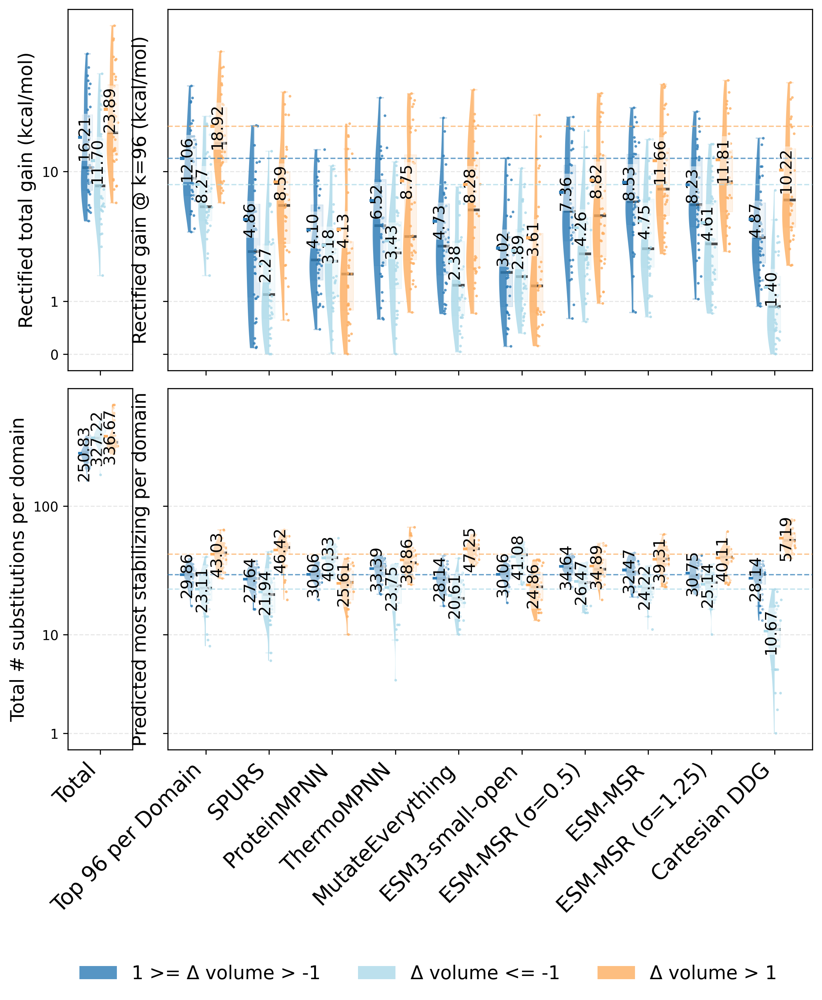

In [53]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

current_feats = ['delta_kdh', 'delta_vol', 'rel_ASA', 'ddG']

subset2 = [f'{c}_in_topk_96' for c in subset if c != 'ddG']
subset2 += ['ddG']

db_fig = db_complete[[c for c in db_complete if c in subset or c in current_feats or c == 'code']].dropna(subset=current_feats)
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=96)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0

db_fig = db_fig.drop(subset[:-1], axis=1)
db_fig = db_fig.rename({'upper_bound_in_topk96': 'Top 96 per Domain',
                        'ProteinMPNN_in_topk96': 'ProteinMPNN',
                        'ThermoMPNN_in_topk96': 'ThermoMPNN',
                        'MutateEverything_in_topk96': 'MutateEverything', 
                        'ESM3-small-open_in_topk96': 'ESM3-small-open',
                        'ESM-MSR_in_topk96': 'ESM-MSR',
                        'ESM-MSR (σ=0.5)_in_topk96': 'ESM-MSR (σ=0.5)',
                        'ESM-MSR (σ=1.25)_in_topk96': 'ESM-MSR (σ=1.25)',
                        'SPURS_in_topk96': 'SPURS',
                        'Rosetta Cartesian DDG_in_topk96': 'Cartesian DDG',
                        'delta_kdh': 'Δ hydrophobicity', 
                        'delta_vol': 'Δ volume', 
                        'rel_ASA': 'relative ASA', 
                        'neff': 'N eff. seqs'}, axis=1)

db_fig['Total'] = db_fig['ddG']

d, models, fig = analysis_utils_msr.compare_performance_per_group(
                        db_fig,
                        split_col = 'Δ volume',
                        split_col_2 = None,
                        threshold_1 = 1, 
                        threshold_2 = -1, 
                        measurement = 'ddG',
                        statistic = 'net_stabilization',
                        #statistic_2 = 'weighted_spearman',
                        #n_bootstraps = 10,
                        #count_muts = True,
                        subset=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG', 'ddG'],
                        grouper='code',
                        order=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG'],
                        #plots='top',
                        drop_label = True,
                        split_last = True,
                        legend_loc = 'below',
                        #saveloc_perf = 'tmp.csv',
                        #show_boxes = True,
                        figsize = (10,10),
                        #annotation_position = 'above',
                        orientation='vertical',
                        #alt_stat_name='Rectified gain @ k=96',
                        #duplicates=True,
                        split_left_model=True,
                        left_group_label = 'Rectified total gain (kcal/mol)',
                        right_group_label = 'Rectified gain @ k=96 (kcal/mol)',
                        # scaffold order is col1 & col2 > T, col1 < T & col2 > T, col1 > T and col2 < T, col1 & col2 < T
                        )

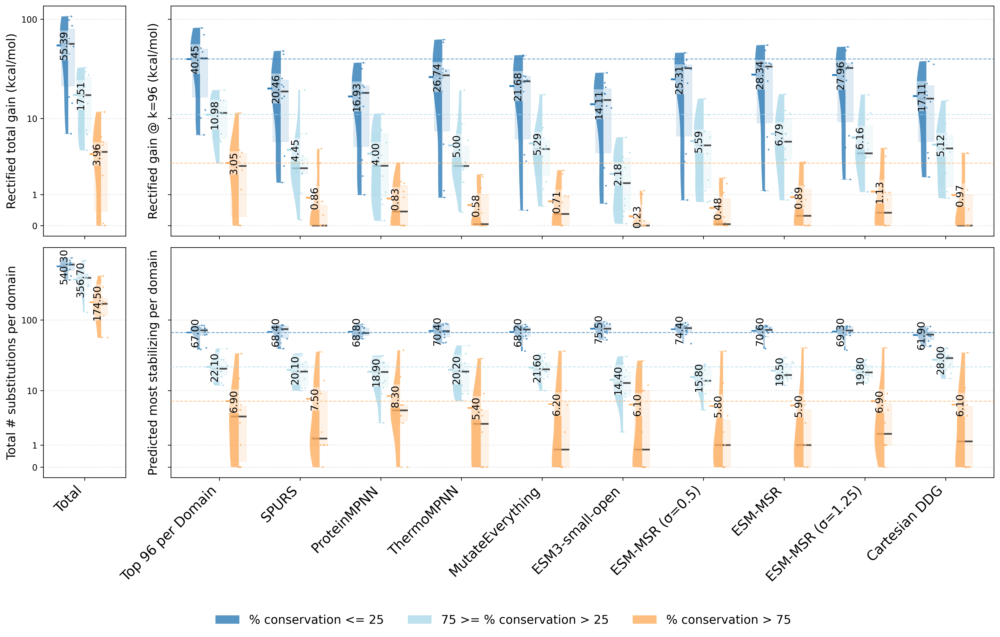

In [54]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)
current_feats2 = ['conservation', 'n_seqs', 'ddG']

db_fig = db_complete[[c for c in db_complete if c in subset or c in current_feats2 or c == 'code']].dropna(subset=current_feats2)
db_fig = db_fig.loc[db_fig['n_seqs'] > 2]
db_fig = topk_by_group(db_fig, 'code', 'ESM3-small-open', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=0.5)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ESM-MSR (σ=1.25)', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'MutateEverything', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ThermoMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'SPURS', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'ProteinMPNN', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'Rosetta Cartesian DDG', 'ddG', set_k=96)
db_fig = topk_by_group(db_fig, 'code', 'upper_bound', 'ddG', set_k=96)

db_fig.loc[db_fig['ddG']<0, 'ddG'] = 0

db_fig = db_fig.drop(subset[:-1], axis=1)
db_fig = db_fig.rename({'upper_bound_in_topk96': 'Top 96 per Domain',
                        'ProteinMPNN_in_topk96': 'ProteinMPNN',
                        'ThermoMPNN_in_topk96': 'ThermoMPNN',
                        'MutateEverything_in_topk96': 'MutateEverything', 
                        'ESM3-small-open_in_topk96': 'ESM3-small-open',
                        'ESM-MSR_in_topk96': 'ESM-MSR',
                        'ESM-MSR (σ=0.5)_in_topk96': 'ESM-MSR (σ=0.5)',
                        'ESM-MSR (σ=1.25)_in_topk96': 'ESM-MSR (σ=1.25)',
                        'SPURS_in_topk96': 'SPURS',
                        'Rosetta Cartesian DDG_in_topk96': 'Cartesian DDG',
                        'delta_kdh': 'Δ hydrophobicity', 
                        'delta_vol': 'Δ volume', 
                        'rel_ASA': 'relative ASA', 
                        'neff': 'N eff. seqs',
                        'conservation': '% conservation'}, axis=1)
db_fig['Total'] = db_fig['ddG']

d, models, fig = analysis_utils_msr.compare_performance_per_group(
                        db_fig,
                        split_col = '% conservation',
                        #split_col_2 = 'delta_kdh',
                        threshold_1 = 75, 
                        threshold_2 = 25, 
                        measurement = 'ddG',
                        statistic = 'net_stabilization',
                        #statistic_2 = 'weighted_spearman',
                        #n_bootstraps = 10,
                        #count_muts = True,
                        subset=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG', 'ddG'],
                        grouper='code',
                        order=['Total', 'Top 96 per Domain', 'SPURS', 'ProteinMPNN', 'ThermoMPNN', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR (σ=0.5)', 'ESM-MSR', 'ESM-MSR (σ=1.25)', 'Cartesian DDG'],
                        legend_order=['% conservation <= 25', '75 >= % conservation > 25', '% conservation > 75'],
                        #plots='top',
                        drop_label = True,
                        split_last = True,
                        legend_loc = 'below',
                        #saveloc_perf = 'tmp.csv',
                        #show_boxes = True,
                        figsize = (20,10),
                        #annotation_position = 'above',
                        orientation='vertical',
                        #alt_stat_name='Rectified gain @ k=96',
                        #duplicates=True,
                        split_left_model=True,
                        left_group_label = 'Rectified total gain (kcal/mol)',
                        right_group_label = 'Rectified gain @ k=96 (kcal/mol)',
                        # scaffold order is col1 & col2 > T, col1 < T & col2 > T, col1 > T and col2 < T, col1 & col2 < T
                        )

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.lines as mlines
from matplotlib.ticker import FormatStrFormatter

def plot_refined_preference_ring(df, score_col, mut_col='mut_type', protein_col=None,
                                 use_wt=False, normalize=False, 
                                 scale_type='dipolar', center_zero=True, 
                                 bezier_tension=0.5, seq_dist_threshold=0,
                                 scale_lw_by_count=False, max_lw=2.0, 
                                 figsize=(8, 8), edge_cmap=None):
    """
    Creates a clustered circular graph for double mutation preferences.
    Features vectorized parsing, sequence distance filtering, macro-averaging,
    wild-type/mutant toggling, symmetric diverging scales, logarithmic count-based 
    thickness (floor=0), and stroked inner labels.
    """
    
    # 1. Validation Checks
    assert isinstance(df, pd.DataFrame), "Input df must be a pandas DataFrame."
    assert mut_col in df.columns, f"Mutation column '{mut_col}' not found."
    assert score_col in df.columns, f"Score column '{score_col}' not found."
    assert scale_type in ['dipolar', 'unipolar'], "scale_type must be 'dipolar' or 'unipolar'."
    if df.empty:
        raise ValueError("The provided DataFrame is empty.")
        
    if edge_cmap is None:
        edge_cmap = 'RdBu' if scale_type == 'dipolar' else 'Greens'
    
    # 2. Vectorized Parsing & Filtering
    extracted = df[mut_col].str.extract(r'^([A-Z])(\d+)([A-Z]):([A-Z])(\d+)([A-Z])$')
    extracted.columns = ['wt1', 'pos1', 'mut1', 'wt2', 'pos2', 'mut2']
    
    if extracted.isna().any().any():
        bad_idx = extracted.isna().any(axis=1).idxmax()
        raise AssertionError(f"Regex failed parsing on value: {df.loc[bad_idx, mut_col]}")
        
    pos1 = pd.to_numeric(extracted['pos1'])
    pos2 = pd.to_numeric(extracted['pos2'])
    
    dist_mask = (pos1 - pos2).abs() > seq_dist_threshold
    
    df_temp = df[dist_mask].copy()
    extracted_filtered = extracted[dist_mask]
    
    if df_temp.empty:
        raise ValueError(f"No data remaining after applying seq_dist_threshold={seq_dist_threshold}.")
        
    if use_wt:
        df_temp['parsed_pair'] = [tuple(sorted([a, b])) for a, b in 
                                  zip(extracted_filtered['wt1'], extracted_filtered['wt2'])]
    else:
        df_temp['parsed_pair'] = [tuple(sorted([a, b])) for a, b in 
                                  zip(extracted_filtered['mut1'], extracted_filtered['mut2'])]
    
    # Calculate absolute frequency of each pair before macro-averaging
    pair_counts = df_temp.groupby('parsed_pair').size().reset_index(name='pair_count')
    
    # 3. Aggregation Strategy
    if protein_col is not None:
        assert protein_col in df_temp.columns, f"Protein column '{protein_col}' not found."
        
        if normalize:
            df_temp['target_score'] = df_temp.groupby(protein_col)[score_col].transform(
                lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0.0
            )
        else:
            df_temp['target_score'] = df_temp[score_col]
            
        protein_agg = df_temp.groupby([protein_col, 'parsed_pair'])['target_score'].mean().reset_index()
        agg_df = protein_agg.groupby('parsed_pair')['target_score'].mean().reset_index()
        agg_df['plot_score'] = agg_df['target_score']
        
    else:
        agg_df = df_temp.groupby('parsed_pair')[score_col].mean().reset_index()
        
        if normalize:
            mean_score = agg_df[score_col].mean()
            std_score = agg_df[score_col].std()
            assert std_score > 0, "Standard deviation is 0; cannot normalize identical scores."
            agg_df['plot_score'] = (agg_df[score_col] - mean_score) / std_score
        else:
            agg_df['plot_score'] = agg_df[score_col]
            
    # Merge the frequency counts into the aggregated dataframe
    agg_df = pd.merge(agg_df, pair_counts, on='parsed_pair')
        
    # 4. Strict Linear Colormap Normalization Math
    v_max = agg_df['plot_score'].max()
    v_min = agg_df['plot_score'].min()
    
    if scale_type == 'dipolar' and center_zero:
        abs_max = max(abs(v_min), abs(v_max))
        if abs_max == 0: 
            abs_max = 1.0
        norm = plt.Normalize(vmin=-abs_max, vmax=abs_max)
        agg_df['magnitude'] = agg_df['plot_score'].abs()
    else:
        norm = plt.Normalize(vmin=v_min, vmax=v_max)
        if scale_type == 'unipolar':
            agg_df['magnitude'] = agg_df['plot_score'] - v_min
        else:
            agg_df['magnitude'] = agg_df['plot_score'].abs()

    # 5. Thickness and Z-Order Sorting
    if scale_lw_by_count:
        max_count = agg_df['pair_count'].max()
        if max_count <= 1:
            agg_df['lw'] = max_lw  # Fallback if the entire dataset is singletons
        else:
            # Logarithmic scaling mapping log(count) to max_lw
            # log(1) evaluates to 0, completely hiding single-observation edges
            agg_df['lw'] = (np.log(np.maximum(agg_df['pair_count'], 1)) / np.log(max_count)) * max_lw
    else:
        max_mag = agg_df['magnitude'].max()
        assert max_mag > 0, "Maximum calculated magnitude is 0; cannot scale line widths."
        agg_df['lw'] = ((agg_df['magnitude'] / max_mag) ** 1.5) * max_lw
        
    # Draw the thickest lines (strongest signals/highest counts) last so they sit on top
    agg_df = agg_df.sort_values(by='lw', ascending=True)
    
    # 6. Define Clusters and Calculate Angular Positions
    categories = {
        'Hydrophobic': (['A', 'V', 'L', 'I', 'M', 'F', 'W', 'P', 'G'], plt.cm.Blues),
        'Polar':       (['S', 'T', 'Y', 'N', 'Q'], plt.cm.Greens), 
        'Positive':    (['R', 'H', 'K'], plt.cm.Reds),
        'Negative':    (['D', 'E'], plt.cm.Purples),
        'Special':     (['C'], plt.cm.Wistia) 
    }
    
    total_aas = 20
    num_clusters = len(categories)
    gap_fraction = 0.04 
    total_gap_space = 2 * np.pi * (gap_fraction * num_clusters)
    space_per_aa = (2 * np.pi - total_gap_space) / total_aas
    
    node_positions, node_angles, node_colors = {}, {}, {}
    ordered_aas = []
    
    current_angle = 0.0
    for cat, (aas, cmap) in categories.items():
        colors = cmap(np.linspace(0.4, 0.9, len(aas)))
        for aa, color in zip(aas, colors):
            node_positions[aa] = (np.cos(current_angle), np.sin(current_angle))
            node_angles[aa] = current_angle
            node_colors[aa] = color
            ordered_aas.append(aa)
            current_angle += space_per_aa
        current_angle += (2 * np.pi * gap_fraction)
        
    # 7. Plotting - ADDED dpi=300
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.set_aspect('equal')
    ax.axis('off')
    
    cmap_edges = plt.get_cmap(edge_cmap)
    
    # Draw Edges
    for _, row in agg_df.iterrows():
        # Optimization: Skip rendering entirely if log scaling resulted in an invisible line
        if scale_lw_by_count and row['lw'] == 0:
            continue
            
        aa1, aa2 = row['parsed_pair']
        p1 = node_positions[aa1]
        p2 = node_positions[aa2]
        edge_color = cmap_edges(norm(row['plot_score']))
        
        if aa1 == aa2:
            loop_control = (p1[0] * 1.5, p1[1] * 1.5)
            path_data = [
                (mpath.Path.MOVETO, p1),
                (mpath.Path.CURVE3, loop_control),
                (mpath.Path.CURVE3, p1)
            ]
        else:
            theta1 = node_angles[aa1]
            theta2 = node_angles[aa2]
            
            delta_theta = abs(theta1 - theta2)
            if delta_theta > np.pi:
                delta_theta = 2 * np.pi - delta_theta
                
            v_x = np.cos(theta1) + np.cos(theta2)
            v_y = np.sin(theta1) + np.sin(theta2)
            
            r_ctrl_base = max(0.0, 1.0 - (delta_theta / np.pi))
            r_ctrl = r_ctrl_base * bezier_tension
            
            norm_v = np.hypot(v_x, v_y)
            if norm_v == 0:
                ctrl_pt = (0, 0)
            else:
                ctrl_pt = ((v_x / norm_v) * r_ctrl, (v_y / norm_v) * r_ctrl)
                
            path_data = [
                (mpath.Path.MOVETO, p1),
                (mpath.Path.CURVE3, ctrl_pt), 
                (mpath.Path.CURVE3, p2)
            ]
            
        codes, verts = zip(*path_data)
        path = mpath.Path(verts, codes)
        
        patch = mpatches.PathPatch(path, fill=False, edgecolor=edge_color, 
                                   linewidth=row['lw'], alpha=0.75, zorder=1, 
                                   capstyle='round')
        ax.add_patch(patch)

    # Draw Nodes
    x_nodes = [node_positions[aa][0] for aa in ordered_aas]
    y_nodes = [node_positions[aa][1] for aa in ordered_aas]
    c_nodes = [node_colors[aa] for aa in ordered_aas]
    
    ax.scatter(x_nodes, y_nodes, s=1200, c=c_nodes, edgecolor='black', linewidth=1.5, zorder=2)
    
    # Label Nodes - UPDATED fontsize=11
    for aa in ordered_aas:
        x, y = node_positions[aa]
        ax.text(x, y, aa, fontsize=11, fontweight='bold', color='white',
                ha='center', va='center', zorder=3,
                path_effects=[pe.withStroke(linewidth=3, foreground='black')])

    # Add Primary Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap_edges, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, aspect=20)
    
    if protein_col is not None:
        score_label = "Macro-Avg Per-Protein Z-Score" if normalize else f"Macro-Avg {score_col}"
    else:
        score_label = f"Z-Score of {score_col}" if normalize else f"Aggregated {score_col}"
        
    # UPDATED: Uniform fontsize=11 and locked format
    cbar.set_label(score_label, fontsize=11, fontweight='bold')
    cbar.ax.tick_params(labelsize=11)
    cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    # Add Secondary Axis to Colorbar
    if normalize and protein_col is None:
        def z_to_raw(z):
            return z * std_score + mean_score
        def raw_to_z(raw):
            return (raw - mean_score) / std_score
            
        secax = cbar.ax.secondary_yaxis('left', functions=(z_to_raw, raw_to_z))
        
        # UPDATED: Uniform fontsize=11 and locked format
        secax.set_ylabel(f"Raw Aggregated {score_col}", fontsize=11, labelpad=10)
        secax.tick_params(labelsize=11)
        secax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        
    # Generate Line Width Legend if scaling by count
    if scale_lw_by_count:
        legend_vals = [
            agg_df['pair_count'].min(),
            int(agg_df['pair_count'].median()),
            agg_df['pair_count'].max()
        ]
        # Remove duplicates if data is highly uniform
        legend_vals = sorted(list(set(legend_vals))) 
        
        legend_lines = []
        for val in legend_vals:
            if max_count <= 1:
                w = max_lw
            else:
                w = (np.log(max(val, 1)) / np.log(max_count)) * max_lw
                
            line = mlines.Line2D([], [], color='dimgray', linewidth=w, label=f'{val:,}')
            legend_lines.append(line)
            
        # UPDATED: Enforced font size 11 on legend
        ax.legend(handles=legend_lines, title="Observation Count\n(Log Scaled)", 
                  loc='upper right', bbox_to_anchor=(1.15, 1.05),
                  frameon=False, title_fontproperties={'weight': 'bold', 'size': 11},
                  prop={'size': 11})

    title_scale = "Diverging (Symmetric Scale)" if scale_type == 'dipolar' else "Sequential"
    title_target = "Wild-Type" if use_wt else "Mutant"
    #plt.title(f"Comprehensive {title_target} Pairwise Signals ({title_scale})", 
    #          fontsize=18, pad=20, fontweight='bold')
    plt.tight_layout()
    
    return fig, ax

In [56]:
import pandas as pd
from esm_msr import preprocessing

split_file = f'/home/sareeves/software/esm-msr/data/hyperopt_splits.pkl'

ds = preprocessing.MegaScaleDatasetPreprocessor(
    data_file='/home/sareeves/software/esm-msr/data/tsuboyama/Tsuboyama2023_Dataset2_Dataset3_20230416.csv', 
    af_model_folder='/home/sareeves/software/esm-msr/data/tsuboyama/AlphaFold_model_PDBs'
)

print(f"Creating training splits at {split_file}...")
_ = ds.create_training_splits(str(split_file), -1)

data_scaffold = ds.split_dfs['test']
data_scaffold['mut_structure'] = data_scaffold['mut_structure'].fillna('-')                

required_cols = ['code', 'chain', 'mut_structure', 'pdb_file']

dfs = []
dfs_zs = []

for (code, chain, mut_structure, pdb_file), _ in data_scaffold.groupby(required_cols):
    try:
        df = pd.read_csv(f'/home/sareeves/software/esm-msr/data/inference_full/{code}_{chain}_inference_dist_100.csv')
        dfs.append(df)
        dfz = pd.read_csv(f'/home/sareeves/software/esm-msr/data/inference_zs/{code}_{chain}_inference_dist_100.csv')
        dfs_zs.append(dfz)
    except Exception as e:
        print(e)

df_master = pd.concat(dfs)
df_master_zs = pd.concat(dfs_zs)
df_master

2026-05-22 12:37:35,860 - INFO - Loaded raw data: 776298 entries from /home/sareeves/software/esm-msr/data/tsuboyama/Tsuboyama2023_Dataset2_Dataset3_20230416.csv
2026-05-22 12:37:40,411 - INFO - Reduced to: 542229 entries after basic filtering
2026-05-22 12:37:40,416 - INFO - Using split file /home/sareeves/software/esm-msr/data/hyperopt_splits.pkl.


Creating training splits at /home/sareeves/software/esm-msr/data/hyperopt_splits.pkl...


Creating test datasets: 100%|██████████| 34/34 [00:00<00:00, 44.26it/s]


Scaffold train : 127 unique structures:
['1AOY', '1F0M', '1K1V', '1PSE', '1PV0', '1QKH', '1QP2', '1TG0', '1URF', '1V1C', '1WCL', '1YP5', '2BTT', '2D1U', '2EXD', '2JN4', '2JTV', '2K1B', '2K28', '2K52_L42A', '2K52_F21S', '2K9D', '2KCM', '2KFV', '2KRS_W42A', '2KRS_Y53S', '2KRU', '2KT8_V15A', '2KT8_G54S', '2KVS', '2KVT', '2KYB_K55A', '2KYB_G2S', '2L09', '2L33', '2L6Q', '2LC2', '2LGW', '2LQK', '2LVN', '2LYP_V26S', '2LYP_P41A', '2LYQ', '2LYR', '2M0Y', '2M2J', '2M2L', '2M7O_I21A', '2M8E', '2MCH', '2MCK', '2MI6', '2MKX_L11A', '2MKX_N29S', '2MXD', '2MYX', '2N88', '2O2W', '2OCH', '2WNM', '3L1X', '3V1A', '3ZGK', '4C26', '4G3O', '5GU9_V60D', '5GU9_L66K', '5JRT', '5KPH', '5OAO', '5UP5', '6ACV', '6EWS', '6EWU', '6IWS', '6OBK', '6YSE', '7JJK', 'EEHEE_rd3_0130', 'EEHEE_rd3_0146', 'EEHEE_rd3_0602', 'EEHEE_rd3_0657', 'EEHEE_rd3_0809', 'EEHEE_rd3_1049', 'EEHEE_rd3_1367', 'EEHEE_rd3_1498', 'EEHEE_rd3_1587', 'EEHEE_rd3_1810', 'EEHEE_rd3_1818', 'EEHEE_rd4_0003', 'EEHEE_rd4_0005', 'EEHEE_rd4_0308', 'EEHEE_rd

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,combined_pred,combined_dddg_pred,wt_lora_pred_additive,wt_lora_dddg_pred,mt_lora_pred_additive,mt_lora_dddg_pred,combined_pred_additive,dist
0,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A,0.037174,-0.116350,-0.039588,-0.076762,NaN,NaN,NaN,NaN,NaN,NaN
1,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1C,0.269181,0.209697,0.239439,-0.029742,NaN,NaN,NaN,NaN,NaN,NaN
2,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1D,-0.017855,-0.131394,-0.074624,-0.056769,NaN,NaN,NaN,NaN,NaN,NaN
3,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1E,-0.049946,-0.157039,-0.103493,-0.053546,NaN,NaN,NaN,NaN,NaN,NaN
4,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1F,0.028291,-0.060296,-0.016002,-0.044293,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425462,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,L48Y:E49S,-0.148574,-0.346819,-0.247697,0.009472,-0.088364,-0.06021,-0.425973,0.079154,-0.257169,4.450862
425463,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,L48Y:E49T,-0.158504,-0.408892,-0.283698,-0.043575,-0.098294,-0.06021,-0.381953,-0.026939,-0.240123,4.450862
425464,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,L48Y:E49V,0.609932,0.648641,0.629286,-0.082141,0.670143,-0.06021,0.752713,-0.104072,0.711428,4.450862
425465,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,L48Y:E49W,0.248774,0.048487,0.148631,0.063674,0.308985,-0.06021,-0.139072,0.187559,0.084956,4.450862


In [ ]:
from analysis_utils_msr import sum_individual_mutation_scores

#dfd = pd.read_csv('/home/sareeves/software/esm-msr/data/features/1a0f_test_screening.csv')
dfd = df_master
#dfd = dfd.loc[dfd['mut_type'].str.contains(':')].copy()
#dfd.sort_values('combined_dddg_pred', ascending=False)
#dfd = dfd.rename(columns={'combined_dddg_pred': 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred': 'Avg. Stabilization (ΔΔG; kcal/mol)'})
dfd['uid'] = dfd['code'] + '_' + dfd['chain'] + '_' + dfd['mut_type']
dfd = dfd.set_index('uid')
#dfd

#dfd = pd.read_csv('/home/sareeves/software/esm-msr/data/features/1a0f_test_screening.csv')
dfd_zs = df_master_zs
dfd_zs['uid'] = dfd_zs['code'] + '_' + dfd_zs['chain'] + '_' + dfd_zs['mut_type']
dfd_zs = dfd_zs.set_index('uid')

target_col = 'combined_pred'

# 1. Calculate the target mean and stdev from dfd
#mean_target = dfd[target_col].mean()
#std_target = dfd[target_col].std()

# 2. Calculate the source mean and stdev from dfd_zs
#mean_source = dfd_zs[target_col].mean()
#std_source = dfd_zs[target_col].std()

# 3. Assert to prevent division by zero in case of uniform predictions
#assert std_source > 0, "Source standard deviation is 0; cannot recalibrate uniform data."

# 4. Apply the recalibration transformation
#dfd_zs[target_col+'_recalibrated'] = (dfd_zs[target_col] - mean_source) * (std_target / std_source) + mean_target

#dfd_zs = sum_individual_mutation_scores(dfd_zs, target_col+'_recalibrated', target_col+'_recalibrated_additive')
#dfd_zs[target_col+'_recalibrated_dddg'] = dfd_zs[target_col+'_recalibrated'] - dfd_zs[target_col+'_recalibrated_additive']

dfd[['mut1', 'mut2']] = dfd['mut_type'].str.split(':', n=1, expand=True)
dfd['wt1'] = dfd['mut1'].str[0]
dfd['pos1'] = dfd['mut1'].str[1:-1].astype(int)
dfd['mt1'] = dfd['mut1'].str[-1]

dfd_zs[['mut1', 'mut2']] = dfd_zs['mut_type'].str.split(':', n=1, expand=True)
dfd_zs['wt1'] = dfd_zs['mut1'].str[0]
dfd_zs['pos1'] = dfd_zs['mut1'].str[1:-1].astype(int)
dfd_zs['mt1'] = dfd_zs['mut1'].str[-1]

dfd_single = dfd.loc[~dfd['mut_type'].str.contains(':')].copy()
dfd_zs_single = dfd_zs.loc[~dfd_zs['mut_type'].str.contains(':')].copy()

dfd = dfd.loc[dfd['mut_type'].str.contains(':')].copy()
dfd_zs = dfd_zs.loc[dfd_zs['mut_type'].str.contains(':')].copy()

dfd['wt2'] = dfd['mut2'].str[0]
dfd['pos2'] = dfd['mut2'].str[1:-1].astype(int)
dfd['mt2'] = dfd['mut2'].str[-1]

dfd_zs['wt2'] = dfd_zs['mut2'].str[0]
dfd_zs['pos2'] = dfd_zs['mut2'].str[1:-1].astype(int)
dfd_zs['mt2'] = dfd_zs['mut2'].str[-1]

dfd = dfd.rename(columns={'combined_dddg_pred': 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred': 'Avg. Stabilization (ΔΔG; kcal/mol)'})
#dfd_zs = dfd_zs.rename(columns={target_col+'_recalibrated_dddg': 'Avg. Epistasis (δΔΔG; kcal/mol)', target_col+'_recalibrated': 'Avg. Stabilization (ΔΔG; kcal/mol)'})
dfd_zs = dfd_zs.rename(columns={'combined_dddg_pred': 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred': 'Avg. Stabilization (ΔΔG; kcal/mol)'})

dfd_zs_a = dfd_zs.loc[(dfd_zs['mt1']=='A')&(dfd_zs['mt2']=='A')]
dfd_a = dfd.loc[(dfd['mt1']=='A')&(dfd['mt2']=='A')]

dfd_a

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),wt_lora_pred_additive,wt_lora_dddg_pred,...,combined_pred_additive,dist,mut1,mut2,wt1,pos1,mt1,wt2,pos2,mt2
uid,,,,,,,,,,,,,,,,,,,,,
1UFM_A_S1A:S2A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A:S2A,-0.023170,0.000454,-0.011358,0.099694,0.037041,-0.060210,...,-0.111052,3.025274,S1A,S2A,S,1,A,S,2,A
1UFM_A_S1A:G3A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A:G3A,0.050592,-0.002112,0.024240,0.048750,0.110802,-0.060210,...,-0.024510,8.170329,S1A,G3A,S,1,A,G,3,A
1UFM_A_S1A:G4A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A:G4A,0.058605,-0.000679,0.028963,0.055321,0.118815,-0.060210,...,-0.026358,9.190768,S1A,G4A,S,1,A,G,4,A
1UFM_A_S1A:S5A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A:S5A,0.016939,-0.082388,-0.032725,0.062775,0.077150,-0.060210,...,-0.095499,7.256012,S1A,S5A,S,1,A,S,5,A
1UFM_A_S1A:S6A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A:S6A,0.005407,-0.088122,-0.041358,0.041746,0.065617,-0.060210,...,-0.083104,9.843958,S1A,S6A,S,1,A,S,6,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_A_V46A:L48A,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,V46A:L48A,-2.897491,-2.387877,-2.642684,0.282596,-2.837280,-0.060210,...,-2.925280,6.481271,V46A,L48A,V,46,A,L,48,A
r11_233_TrROS_Hall_A_V46A:E49A,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,V46A:E49A,-1.234764,-1.093216,-1.163990,0.014513,-1.174553,-0.060210,...,-1.178503,10.080579,V46A,E49A,V,46,A,E,49,A
r11_233_TrROS_Hall_A_E47A:L48A,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,E47A:L48A,-2.042299,-1.946627,-1.994463,0.093684,-1.982089,-0.060211,...,-2.088147,4.537065,E47A,L48A,E,47,A,L,48,A


In [ ]:
dfd_single

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,combined_pred,combined_dddg_pred,wt_lora_pred_additive,wt_lora_dddg_pred,mt_lora_pred_additive,mt_lora_dddg_pred,combined_pred_additive,dist,mut1,mut2,wt1,pos1,mt1
uid,,,,,,,,,,,,,,,,,,,
1UFM_A_S1A,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1A,0.037174,-0.116350,-0.039588,-0.076762,NaN,NaN,NaN,NaN,NaN,NaN,S1A,None,S,1,A
1UFM_A_S1C,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1C,0.269181,0.209697,0.239439,-0.029742,NaN,NaN,NaN,NaN,NaN,NaN,S1C,None,S,1,C
1UFM_A_S1D,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1D,-0.017855,-0.131394,-0.074624,-0.056769,NaN,NaN,NaN,NaN,NaN,NaN,S1D,None,S,1,D
1UFM_A_S1E,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1E,-0.049946,-0.157039,-0.103493,-0.053546,NaN,NaN,NaN,NaN,NaN,NaN,S1E,None,S,1,E
1UFM_A_S1F,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,S1F,0.028291,-0.060296,-0.016002,-0.044293,NaN,NaN,NaN,NaN,NaN,NaN,S1F,None,S,1,F
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r11_233_TrROS_Hall_A_E49S,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,E49S,0.260443,0.166107,0.213275,-0.047168,NaN,NaN,NaN,NaN,NaN,NaN,E49S,None,E,49,S
r11_233_TrROS_Hall_A_E49T,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,E49T,0.250513,0.210127,0.230320,-0.020193,NaN,NaN,NaN,NaN,NaN,NaN,E49T,None,E,49,T
r11_233_TrROS_Hall_A_E49V,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,E49V,1.018949,1.344793,1.181871,0.162922,NaN,NaN,NaN,NaN,NaN,NaN,E49V,None,E,49,V


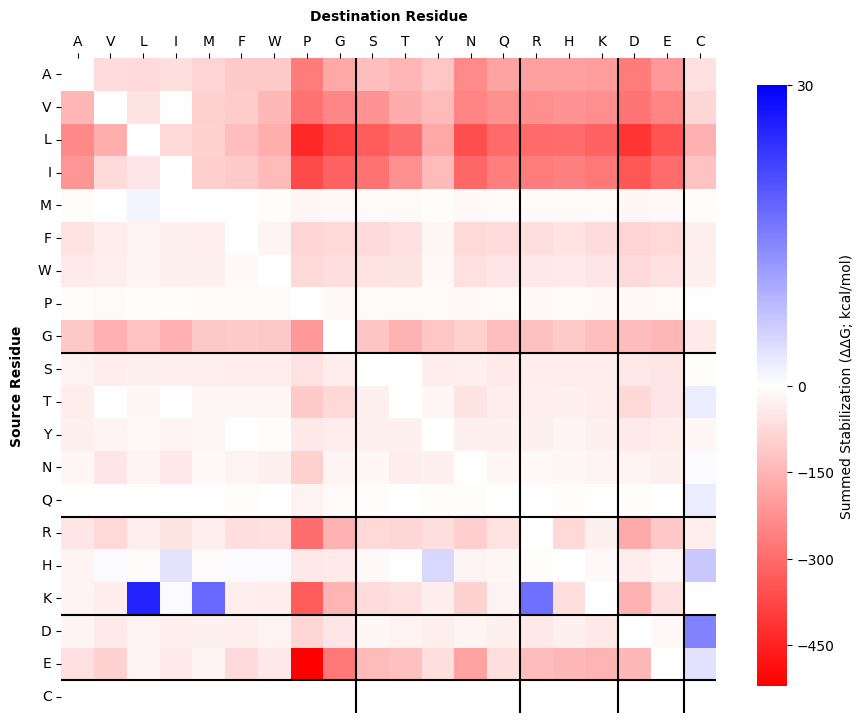

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

def plot_transition_matrix_grouped(df, score_col, wt_col='wt1', mut_col='mt1', 
                                   figsize=(9, 8)):
    """
    Creates a 20x20 transition matrix grouped by biochemical properties.
    Features a custom half-contrast colormap for the positive range and 
    explicitly forces a rounded positive tick on the colorbar.
    """
    # 1. Validation
    if df.empty:
        raise AssertionError("The provided DataFrame is empty.")
    if score_col not in df.columns:
        raise AssertionError(f"Score column '{score_col}' not found in DataFrame.")

    # 2. Define Groups
    categories = {
        'Hydrophobic': ['A', 'V', 'L', 'I', 'M', 'F', 'W', 'P', 'G'],
        'Polar':       ['S', 'T', 'Y', 'N', 'Q'],
        'Positive':    ['R', 'H', 'K'],
        'Negative':    ['D', 'E'],
        'Special':     ['C']
    }
    
    ordered_aas = []
    group_bounds = []
    current_idx = 0
    
    for cat, aas in categories.items():
        ordered_aas.extend(aas)
        current_idx += len(aas)
        if current_idx < 20:
            group_bounds.append(current_idx)

    # 3. Aggregate and Pivot
    agg_df = df.groupby([wt_col, mut_col])[score_col].sum().reset_index()
    matrix = agg_df.pivot(index=wt_col, columns=mut_col, values=score_col)

    # 4. Force consistent 20x20 grid
    matrix = matrix.reindex(index=ordered_aas, columns=ordered_aas)

    # 5. Extract min/max and dynamically round the positive maximum
    v_min = matrix.min().min()
    v_max = matrix.max().max()
    
    if pd.isna(v_min) or pd.isna(v_max):
        raise ValueError("Matrix contains only NaNs after pivoting.")
    
    v_min_safe = min(v_min, -0.01)
    
    # Round vmax up to the nearest clean interval (e.g., 5, 10, or 20)
    if v_max > 0:
        step = 10 if v_max > 15 else 5
        v_max_safe = np.ceil(v_max / step) * step
    else:
        v_max_safe = 10.0

    norm = mcolors.TwoSlopeNorm(vmin=v_min_safe, vcenter=0., vmax=v_max_safe)

    # 6. Build the Half-Contrast Custom Colormap
    # Negative = Deep Purple (#4a148c), Zero = White (#ffffff), Positive = Soft Purple/Lilac (#ce93d8)
    half_contrast_cmap = mcolors.LinearSegmentedColormap.from_list(
        "RdBu_half", ["#ff0000", "#ffffff", "#0000ff"]
    )

    # 7. Force explicit colorbar ticks to guarantee the positive upper bound is labeled
    # This generates 4 evenly spaced negative ticks, a zero tick, and our new rounded positive max
    neg_ticks = np.linspace(np.floor(v_min_safe/100)*100, 0, 4, endpoint=False)
    cbar_ticks = list(neg_ticks) + [0, v_max_safe]

    # 8. Plotting
    fig, ax = plt.subplots(figsize=figsize)
    
    sns.heatmap(matrix, ax=ax, cmap=half_contrast_cmap, norm=norm,
                annot=False, square=True, 
                cbar_kws={
                    'label': f'Summed Stabilization (ΔΔG; kcal/mol)', 
                    'shrink': 0.8,
                    'ticks': cbar_ticks  # Inject our custom ticks here
                })

    # 9. Draw Group Boundaries
    for b in group_bounds:
        ax.axhline(b, color='black', linewidth=1.5)
        ax.axvline(b, color='black', linewidth=1.5)

    # Formatting
    ax.set_xlabel(f"Destination Residue", fontweight='bold', labelpad=10)
    ax.set_ylabel(f"Source Residue", fontweight='bold', labelpad=10)
    #ax.set_title("Grouped Single Mutation Transition Matrix", fontsize=15, fontweight='bold', pad=20)

    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    plt.yticks(rotation=0)

    plt.tight_layout()
    return fig, ax

# Render the plot
fig, ax = plot_transition_matrix_grouped(dfd_single, score_col='combined_pred')
plt.show()

Filtered 0 rows with sequence distance < 0.


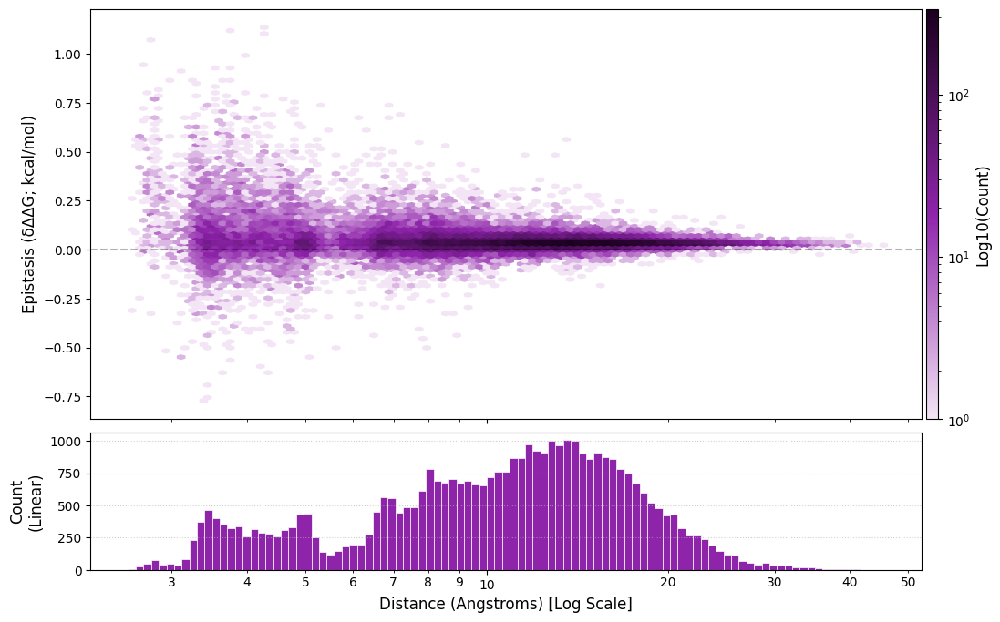

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors

def dist_plot(df):
    # Prevent silent failures if the dataframe is missing required inputs
    if 'Avg. Epistasis (δΔΔG; kcal/mol)' not in df.columns or 'dist' not in df.columns:
        raise AssertionError("Required columns 'Avg. Epistasis (δΔΔG; kcal/mol)' or 'dist' are missing from df.")

    # --- Sequence Distance Filtering ---
    MIN_SEQ_DIST = 0  
    
    if 'pos1' in df.columns and 'pos2' in df.columns:
        df['seq_dist'] = np.abs(pd.to_numeric(df['pos1']) - pd.to_numeric(df['pos2']))
        
        initial_len = len(df)
        df = df[df['seq_dist'] >= MIN_SEQ_DIST].copy()
        filtered_len = len(df)
        print(f"Filtered {initial_len - filtered_len} rows with sequence distance < {MIN_SEQ_DIST}.")
    else:
        df = df.copy()
        print("Warning: 'pos1' and 'pos2' not found. Skipping sequence distance filtering.")

    # Vectorized absolute value computation
    df['dddg_abs'] = np.abs(df['Avg. Epistasis (δΔΔG; kcal/mol)'])
    df['dddg_raw'] = df['Avg. Epistasis (δΔΔG; kcal/mol)']

    if (df['dist'] <= 0).any():
        raise AssertionError("Values <= 0 found in df['dist']. Logarithmic x-scale requires strictly positive distances.")

    # --- CUSTOM COLORMAP ---
    purple_cmap = mcolors.LinearSegmentedColormap.from_list("PinkPurple", ["#f3e5f5", "#8e24aa", "#1a001e"])

    # --- ADVANCED LAYOUT: GridSpec ---
    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.015], height_ratios=[3, 1], wspace=0.01, hspace=0.05)
    
    ax_scatter = fig.add_subplot(gs[0, 0])
    ax_hist = fig.add_subplot(gs[1, 0], sharex=ax_scatter) 
    cax = fig.add_subplot(gs[0, 1]) 

    # --- TOP PANEL: Scatter Plot with Density ---
    ax_scatter.set_facecolor('white')
    
    hb = ax_scatter.hexbin(
        df['dist'], 
        df['dddg_raw'], 
        gridsize=(100, 60), 
        cmap=purple_cmap,  
        mincnt=1,          
        bins='log',          
        xscale='log'         
    )

    ax_scatter.axhline(0, color='black', linestyle='--', alpha=0.3) 

    max_dist = df['dist'].max()
    if max_dist > 50:
        print(f"Warning: max distance is {max_dist:.1f}. Forcing labels on all log-scale minor ticks will likely cause severe text overlapping.")

    ax_scatter.set_ylabel("Epistasis (δΔΔG; kcal/mol)", fontsize=12)
    #ax_scatter.set_title(f"Interaction vs Distance Density\n(Seq Dist >= {MIN_SEQ_DIST})", fontsize=14, fontweight='bold')

    cb = fig.colorbar(hb, cax=cax)
    cb.set_label('Log10(Count)', fontsize=12)

    # --- BOTTOM PANEL: Distance Population Histogram ---
    min_dist_val = df['dist'].min()
    max_dist_val = df['dist'].max()
    log_bins = np.logspace(np.log10(min_dist_val), np.log10(max_dist_val), 100)
    
    ax_hist.hist(df['dist'], bins=log_bins, color="#8e24aa", edgecolor='white', linewidth=0.5)
    
    ax_hist.set_ylabel("Count\n(Linear)", fontsize=12)
    ax_hist.set_xlabel("Distance (Angstroms) [Log Scale]", fontsize=12)
    ax_hist.set_xscale('log')
    ax_hist.grid(axis='y', linestyle=':', alpha=0.6)

    # --- Formatting Shared Axes ---
    clean_formatter = ticker.FormatStrFormatter('%g')

    ax_hist.xaxis.set_major_formatter(clean_formatter)
    ax_hist.xaxis.set_minor_formatter(clean_formatter)
    
    # FIX: Explicitly target 'both' (major and minor) when hiding labels on the top plot
    ax_scatter.tick_params(axis='x', which='both', labelbottom=False)
    ax_hist.tick_params(axis='x', which='both', labelbottom=True)

    plt.setp(ax_hist.get_xticklabels(which='both'), fontsize=10)
    
    plt.show()

dist_plot(dfd_a)

In [ ]:
dfd_a.sort_values('Avg. Epistasis (δΔΔG; kcal/mol)')

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),wt_lora_pred_additive,wt_lora_dddg_pred,...,dist,mut1,mut2,wt1,pos1,mt1,wt2,pos2,mt2,seq_dist
uid,,,,,,,,,,,,,,,,,,,,,
XX_run1_0461_0006_A_F5A:F25A,/home/sreeves/software/esm-msr/data/tsuboyama/...,XX_run1_0461_0006,A,F5A:F25A,-4.093221,-4.956898,-4.525060,-0.771983,-4.033010,-0.060211,...,3.435052,F5A,F25A,F,5,A,F,25,A,20
GG_run5_0637_0006_A_I17A:I22A,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run5_0637_0006,A,I17A:I22A,-1.969169,-3.608493,-2.788831,-0.753372,-1.908958,-0.060210,...,3.469845,I17A,I22A,I,17,A,I,22,A,5
r11_233_TrROS_Hall_A_I9A:L44A,/home/sreeves/software/esm-msr/data/tsuboyama/...,r11_233_TrROS_Hall,A,I9A:L44A,-1.984842,-2.803439,-2.394141,-0.694261,-1.924632,-0.060211,...,3.398646,I9A,L44A,I,9,A,L,44,A,35
EA_run7_1572_0002_A_L14A:L22A,/home/sreeves/software/esm-msr/data/tsuboyama/...,EA_run7_1572_0002,A,L14A:L22A,-2.441374,-2.772564,-2.606969,-0.632746,-2.381163,-0.060210,...,3.654459,L14A,L22A,L,14,A,L,22,A,8
6M3N_A_D27A:V38A,/home/sreeves/software/esm-msr/data/tsuboyama/...,6M3N,A,D27A:V38A,-0.351080,-0.601935,-0.476508,-0.628724,-0.290870,-0.060211,...,4.383109,D27A,V38A,D,27,A,V,38,A,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0244_A_L10A:W25A,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0244,A,L10A:W25A,-5.380240,-2.970036,-4.175138,0.992606,-5.320029,-0.060210,...,3.932034,L10A,W25A,L,10,A,W,25,A,15
HHH_rd1_0142_A_E13A:R36A,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0142,A,E13A:R36A,-2.397966,0.037653,-1.180157,1.072750,-2.337756,-0.060210,...,2.746752,E13A,R36A,E,13,A,R,36,A,23
HHH_rd1_0598_A_I11A:G16A,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0598,A,I11A:G16A,-3.162138,0.262125,-1.450007,1.100507,-3.101928,-0.060210,...,4.304092,I11A,G16A,I,11,A,G,16,A,5


Filtered 0 rows with sequence distance < 0.


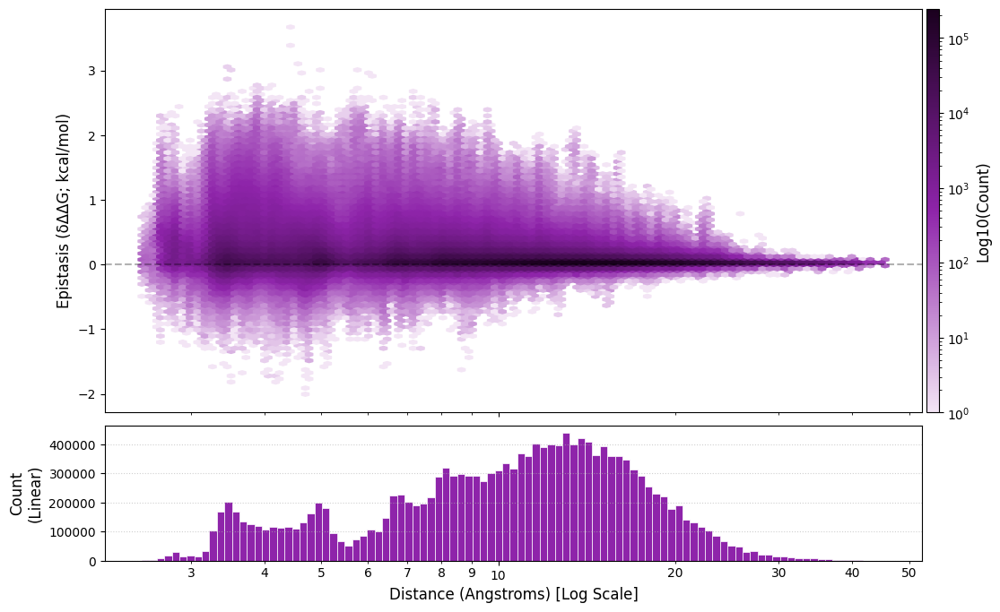

In [ ]:
dist_plot(dfd)

Filtered 0 rows with sequence distance < 0.


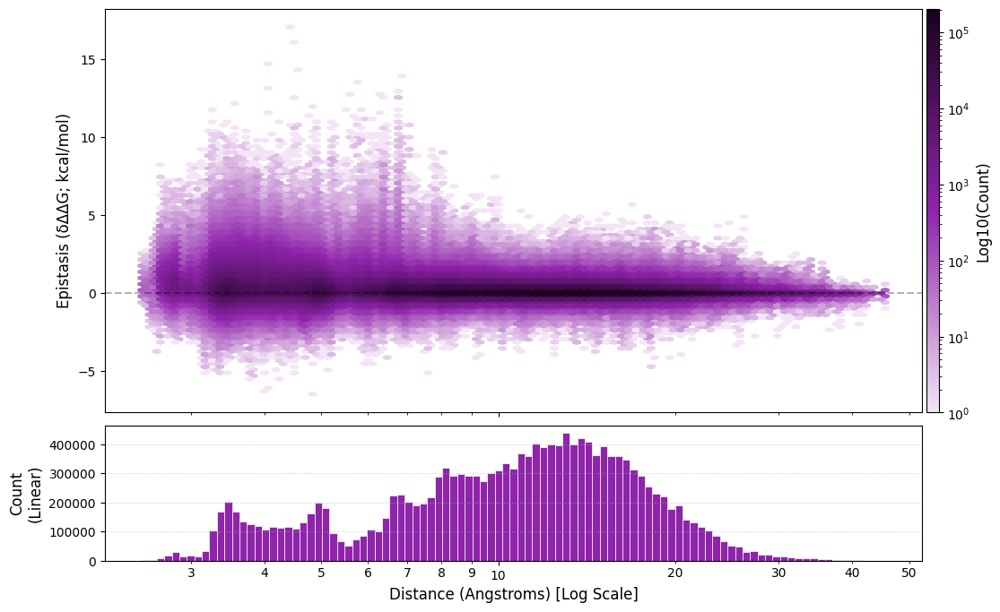

In [ ]:
dist_plot(dfd_zs)

In [ ]:
dfd = dfd.loc[dfd['dist']<=8]
dfd_a = dfd_a.loc[dfd_a['dist']<=8]
dfd_zs = dfd_zs.loc[dfd_zs['dist']<=8]
dfd_zs_a = dfd_zs_a.loc[dfd_zs_a['dist']<=8]

In [ ]:
dfd = dfd.sort_values('Avg. Epistasis (δΔΔG; kcal/mol)')
dfd[['code', 'chain', 'mut_type', 'Avg. Stabilization (ΔΔG; kcal/mol)', 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred_additive', 'dist']].tail(30)

,code,chain,mut_type,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),combined_pred_additive,dist
uid,,,,,,,
GG_run1_1390_0006_A_G16I:V17K,GG_run1_1390_0006,A,G16I:V17K,-1.384956,2.644161,-4.029117,3.463560
1UFM_A_A47R:F69D,1UFM,A,A47R:F69D,-3.272979,2.657154,-5.930133,7.243014
2K5H_A_V46N:V58Y,2K5H,A,V46N:V58Y,-3.624034,2.659893,-6.283927,3.896913
2K5H_G23A_A_V46D:V58H,2K5H_G23A,A,V46D:V58H,-3.321020,2.668180,-5.989200,3.896913
XX_run8_1063_0003_A_L28G:A33W,XX_run8_1063_0003,A,L28G:A33W,-1.871946,2.680197,-4.552144,4.820591
HHH_rd1_0142_A_I16G:A21W,HHH_rd1_0142,A,I16G:A21W,-1.136383,2.685346,-3.821729,5.738926
GG_run1_1390_0006_A_K29D:I38K,GG_run1_1390_0006,A,K29D:I38K,-3.147877,2.692442,-5.840319,3.622638
HHH_rd1_0949_A_L11G:A35F,HHH_rd1_0949,A,L11G:A35F,-3.742938,2.692894,-6.435831,3.828807
2K5H_G23A_A_V46N:V58H,2K5H_G23A,A,V46N:V58H,-3.350919,2.711609,-6.062529,3.896913


In [ ]:
dfd_zs = dfd_zs.sort_values('Avg. Epistasis (δΔΔG; kcal/mol)')
dfd_zs[['code', 'chain', 'mut_type', 'Avg. Stabilization (ΔΔG; kcal/mol)', 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred_additive', 'dist']].tail(30)

,code,chain,mut_type,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),combined_pred_additive,dist
uid,,,,,,,
2RU9_A_I13G:A45Y,2RU9,A,I13G:A45Y,-14.400379,11.091636,-25.492015,6.121000
EA_run7_1572_0002_A_L14D:A25R,EA_run7_1572_0002,A,L14D:A25R,-12.566324,11.114923,-23.681247,5.989429
2K5H_G11S_A_V25G:A34L,2K5H_G11S,A,V25G:A34L,-16.037518,11.139664,-27.177181,5.871535
2K5H_G11S_A_A34M:V58G,2K5H_G11S,A,A34M:V58G,-13.656243,11.163472,-24.819715,5.704249
2K5H_A_A34M:V58G,2K5H,A,A34M:V58G,-12.934489,11.268335,-24.202825,5.704249
GG_run4_1050_0002_A_A25M:I42S,GG_run4_1050_0002,A,A25M:I42S,-12.977412,11.282109,-24.259521,6.784903
GG_run2_0085_0001_A_L14G:A17W,GG_run2_0085_0001,A,L14G:A17W,-5.828356,11.408176,-17.236532,4.758106
GG_run5_0637_0006_A_V14F:I17G,GG_run5_0637_0006,A,V14F:I17G,-8.197753,11.530845,-19.728598,4.081360
GG_run5_1147_0004_A_V14G:A17L,GG_run5_1147_0004,A,V14G:A17L,-8.795726,11.548075,-20.343801,6.362850


In [ ]:
dfd[['code', 'chain', 'mut_type', 'Avg. Stabilization (ΔΔG; kcal/mol)', 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred_additive', 'dist']].head(30)

,code,chain,mut_type,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),combined_pred_additive,dist
uid,,,,,,,
HHH_rd1_0516_A_K22E:K36D,HHH_rd1_0516,A,K22E:K36D,-1.091320,-2.005934,0.914614,4.743188
HHH_rd1_0516_A_K22E:K36E,HHH_rd1_0516,A,K22E:K36E,-0.686627,-1.924215,1.237588,4.743188
XX_run1_0455_0002_A_W24R:W41K,XX_run1_0455_0002,A,W24R:W41K,-2.373771,-1.840114,-0.533657,4.200790
HHH_rd1_0493_A_A12E:N17E,HHH_rd1_0493,A,A12E:N17E,-1.909849,-1.791355,-0.118494,3.514410
HHH_rd1_0516_A_K22F:K36D,HHH_rd1_0516,A,K22F:K36D,0.033840,-1.767756,1.801595,4.743188
XX_run1_0455_0002_A_W24R:W41R,XX_run1_0455_0002,A,W24R:W41R,-2.167770,-1.751493,-0.416277,4.200790
HHH_rd1_0473_A_R22F:K36D,HHH_rd1_0473,A,R22F:K36D,-0.128263,-1.726226,1.597963,4.035986
HHH_rd1_0473_A_R22I:K36D,HHH_rd1_0473,A,R22I:K36D,-0.000700,-1.712264,1.711564,4.035986
GG_run1_1390_0006_A_K29L:L35D,GG_run1_1390_0006,A,K29L:L35D,-1.270670,-1.710477,0.439806,4.220368


In [ ]:
dfd_zs[['code', 'chain', 'mut_type', 'Avg. Stabilization (ΔΔG; kcal/mol)', 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred_additive', 'dist']].head(30)

,code,chain,mut_type,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),combined_pred_additive,dist
uid,,,,,,,
1UFM_A_G33I:E37I,1UFM,A,G33I:E37I,-31.344105,-6.478151,-24.865953,4.902216
HHH_rd1_0473_A_R22V:K36D,HHH_rd1_0473,A,R22V:K36D,-0.617748,-6.301879,5.684132,4.035986
HHH_rd1_0473_A_R22I:K36D,HHH_rd1_0473,A,R22I:K36D,-0.138819,-6.012662,5.873843,4.035986
EA_run7_1572_0002_A_I10K:I12A,EA_run7_1572_0002,A,I10K:I12A,-3.355035,-5.548369,2.193334,3.798224
6M3N_A_F25V:M46V,6M3N,A,F25V:M46V,-11.454027,-5.422570,-6.031458,4.278466
EA_run7_1572_0002_A_I10Q:I12A,EA_run7_1572_0002,A,I10Q:I12A,-3.854372,-5.351842,1.497471,3.798224
EA_run7_1572_0002_A_I10R:I12A,EA_run7_1572_0002,A,I10R:I12A,-3.504170,-5.279722,1.775552,3.798224
EA_run3_0525_0006_A_F3V:A22Y,EA_run3_0525_0006,A,F3V:A22Y,-7.412096,-5.272418,-2.139678,3.808546
EA_run3_0321_0005_A_F21T:I25K,EA_run3_0321_0005,A,F21T:I25K,-10.181495,-5.204949,-4.976546,3.348297


In [ ]:
dfd.loc[dfd['dist']>10].sort_values('Avg. Epistasis (δΔΔG; kcal/mol)')[['code', 'chain', 'mut_type', 'Avg. Stabilization (ΔΔG; kcal/mol)', 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred_additive', 'dist']]

,code,chain,mut_type,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),combined_pred_additive,dist
uid,,,,,,,


(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

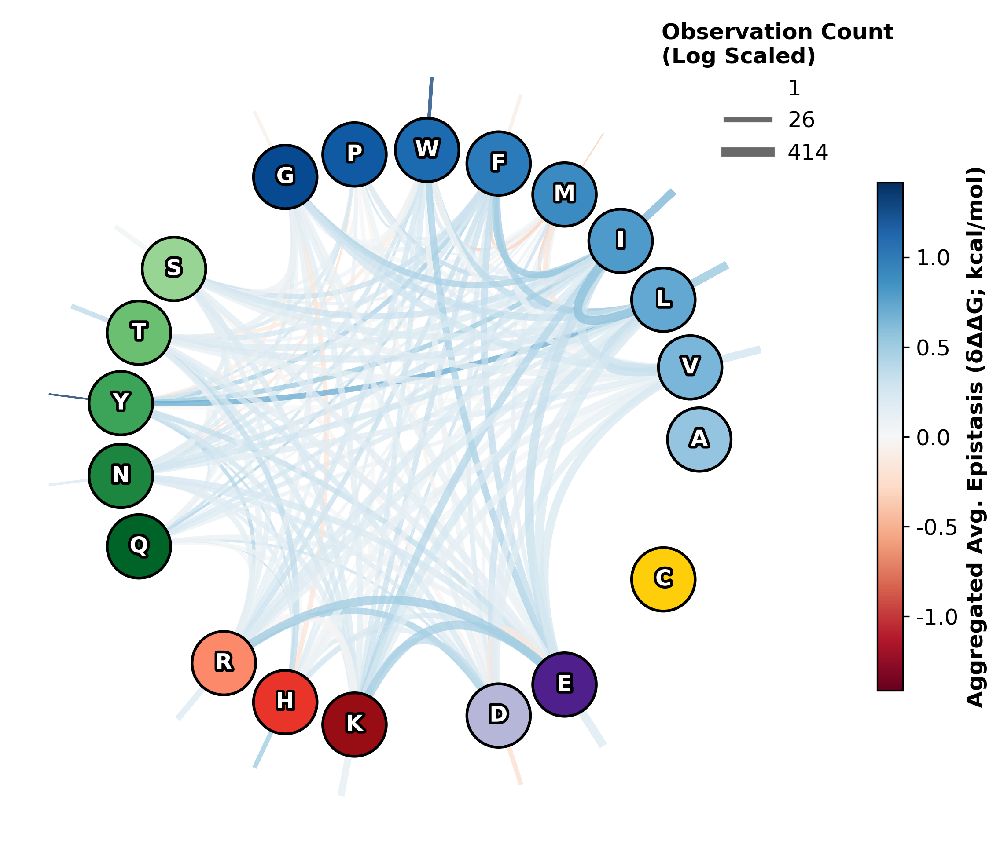

In [ ]:
plot_refined_preference_ring(dfd_zs_a, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=False, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True, max_lw=5)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

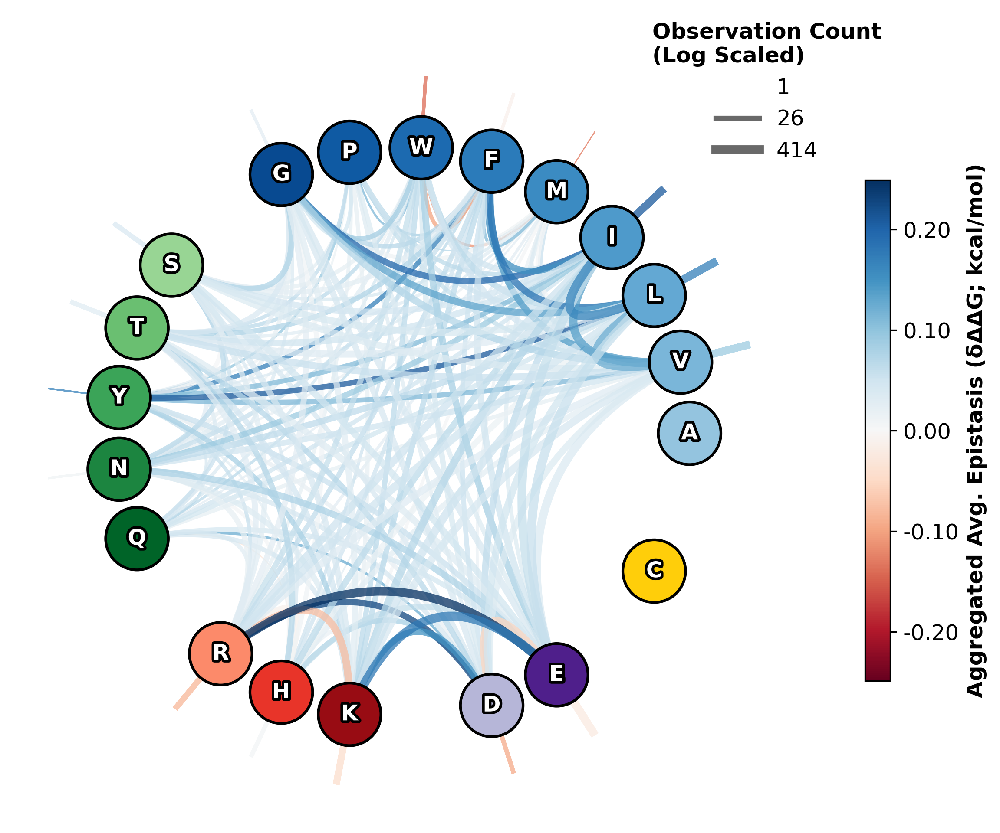

In [ ]:
plot_refined_preference_ring(dfd_a, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=False, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True, max_lw=5)

In [ ]:
# 1. Identify numeric columns
#numeric_cols = dfd_a.select_dtypes(include='number').columns

# 2. Subtract only those columns
# This assumes dfd_a and df2 have the same index and column names
#result = dfd_a.copy()
#result[numeric_cols] = dfd_a[numeric_cols] - dfd_zs_a[numeric_cols]

#plot_refined_preference_ring(result, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

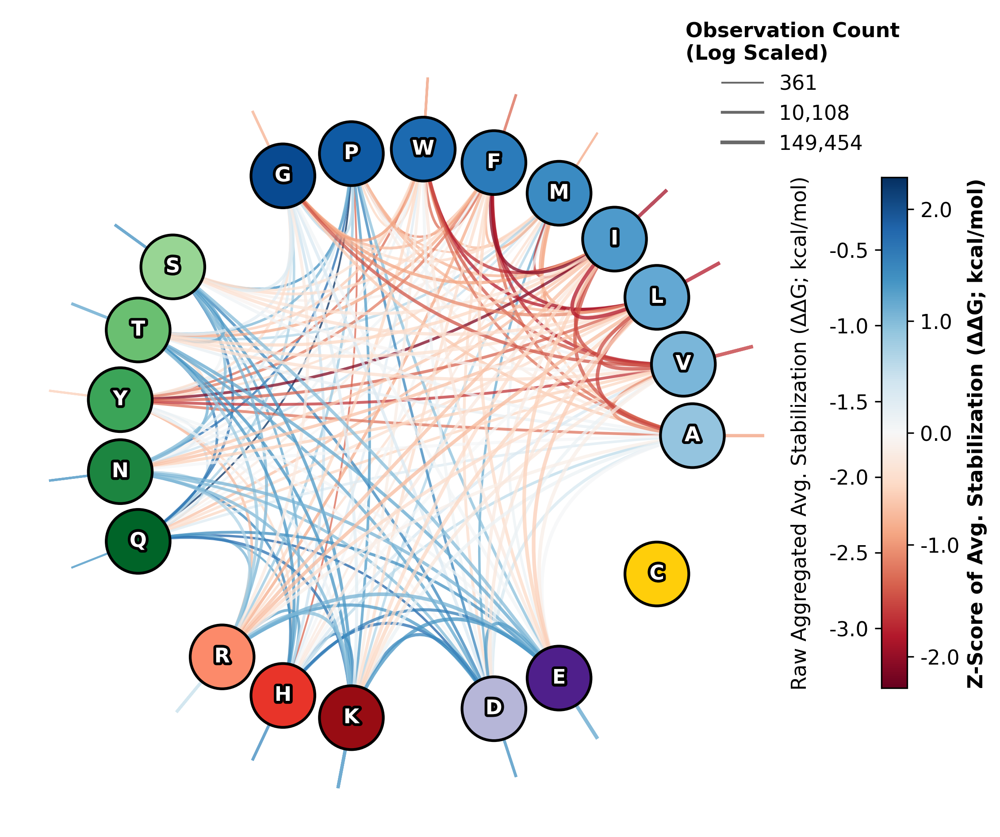

In [ ]:
plot_refined_preference_ring(dfd, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

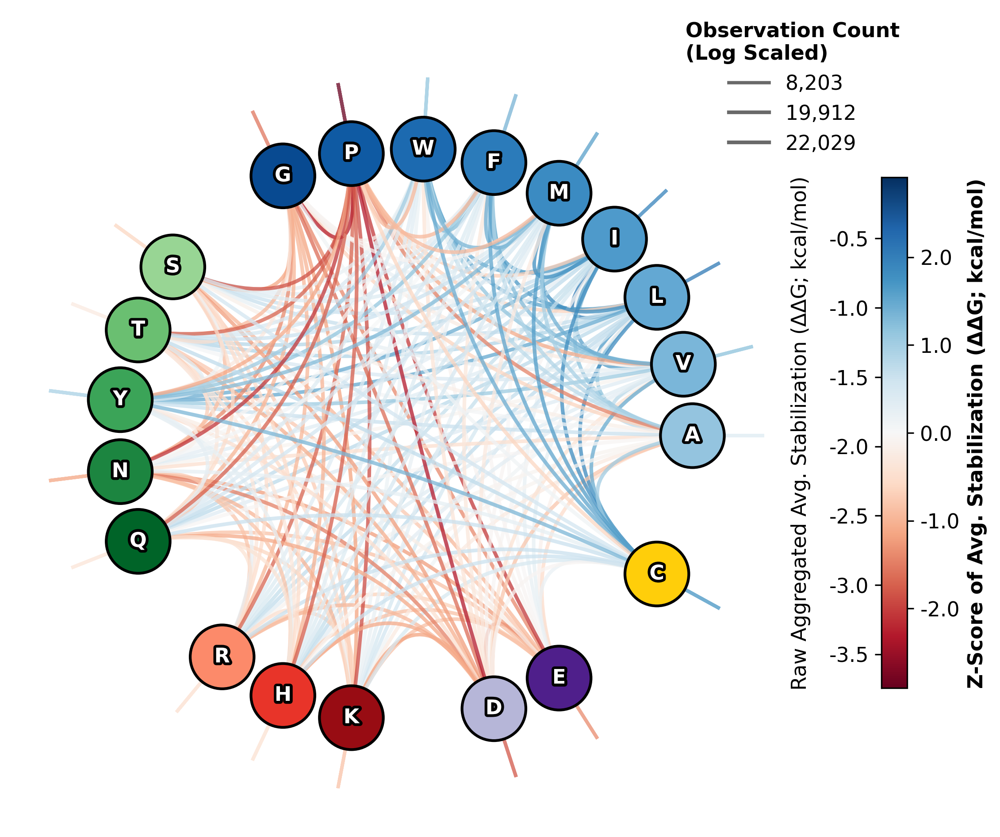

In [ ]:
plot_refined_preference_ring(dfd, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

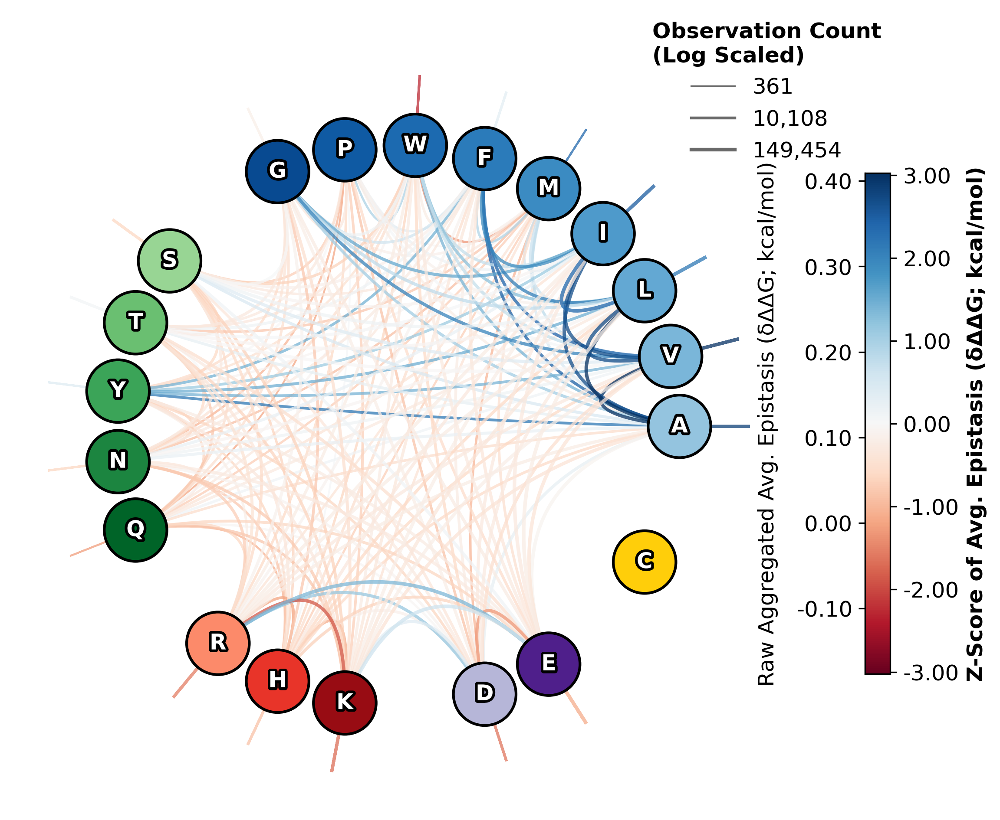

In [ ]:
plot_refined_preference_ring(dfd, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

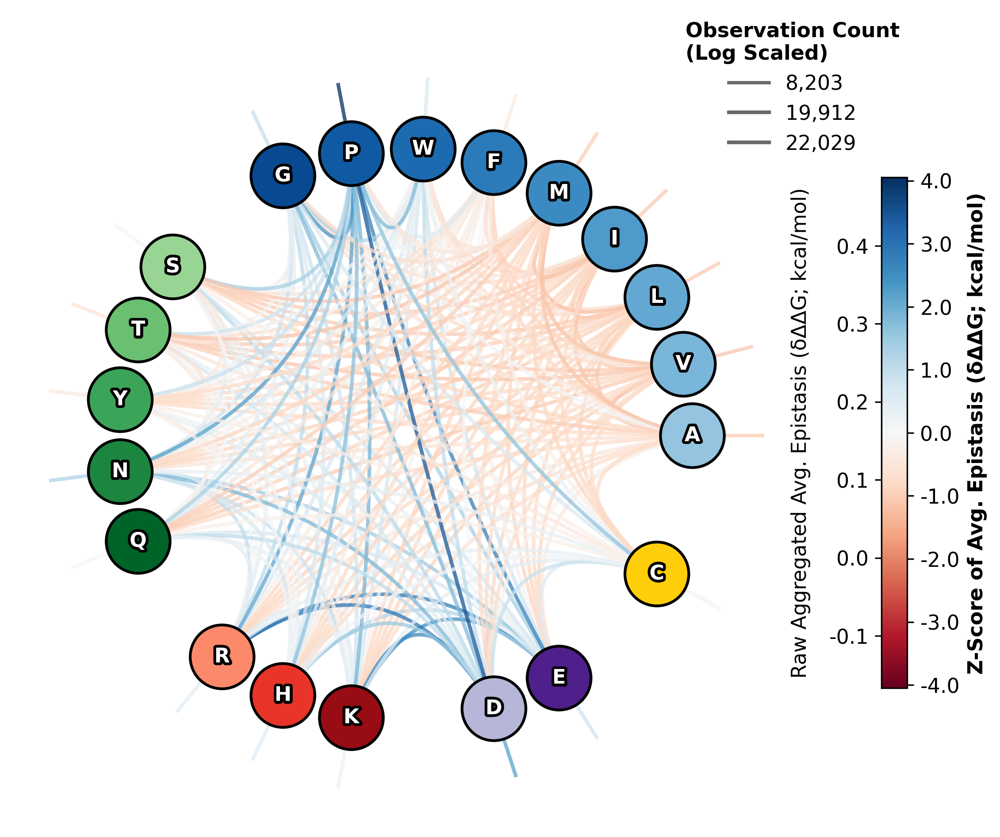

In [ ]:
plot_refined_preference_ring(dfd, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

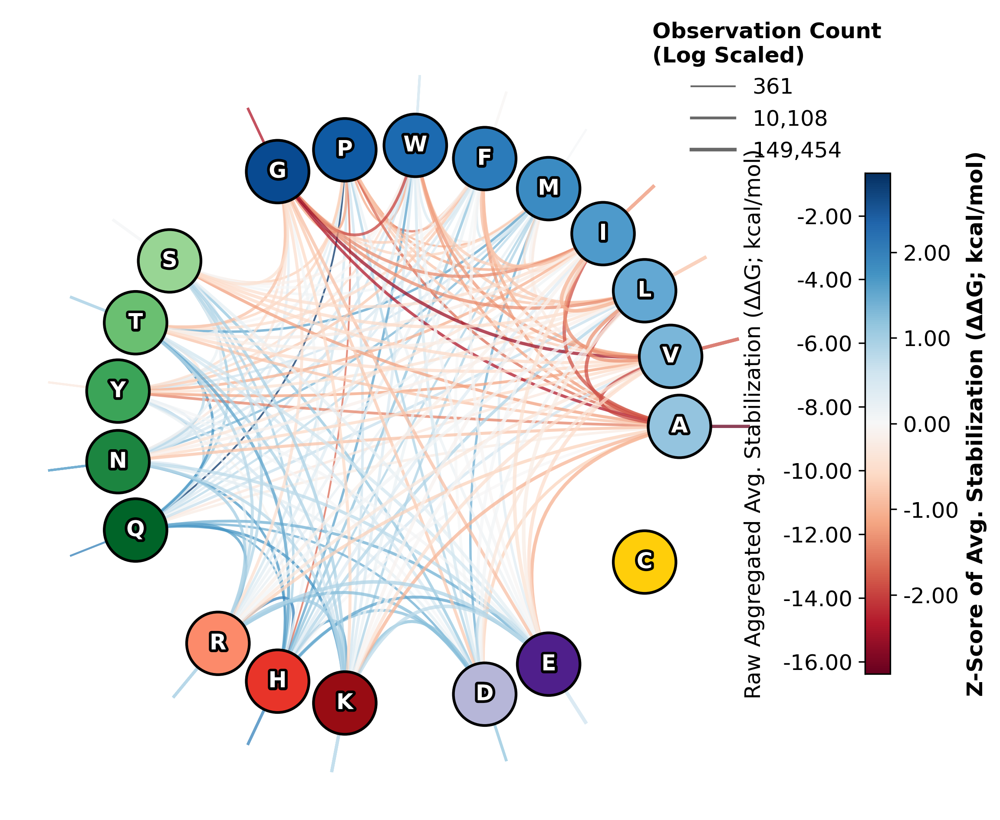

In [ ]:
plot_refined_preference_ring(dfd_zs, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

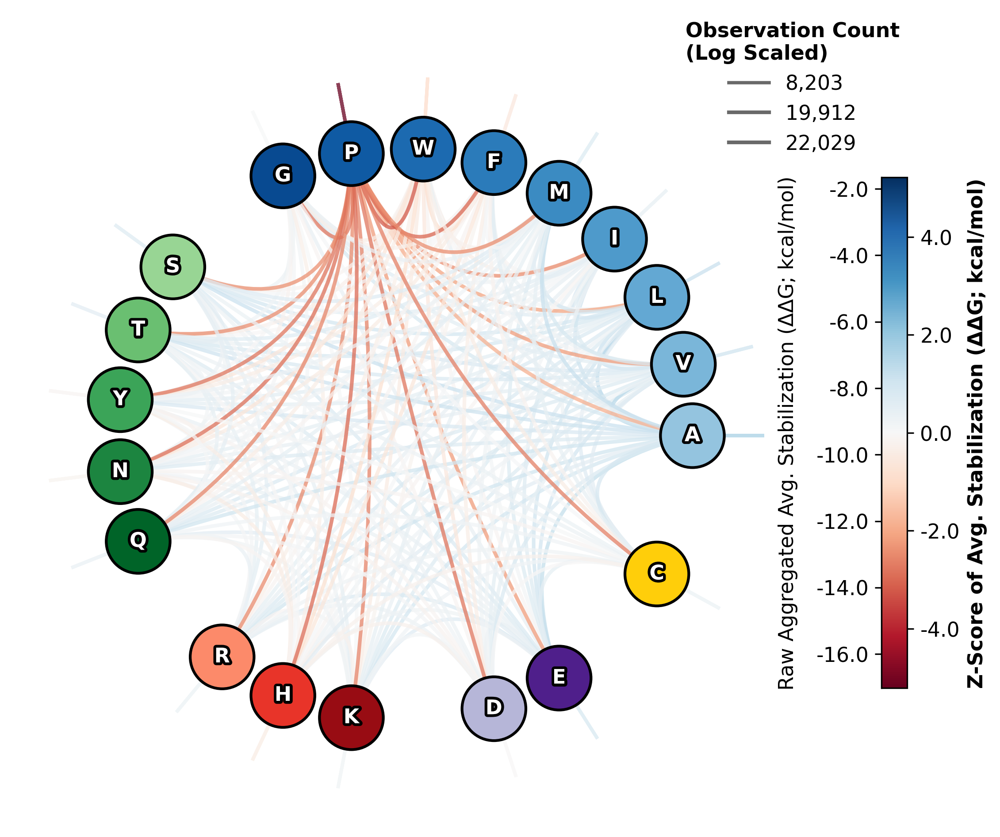

In [ ]:
plot_refined_preference_ring(dfd_zs, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

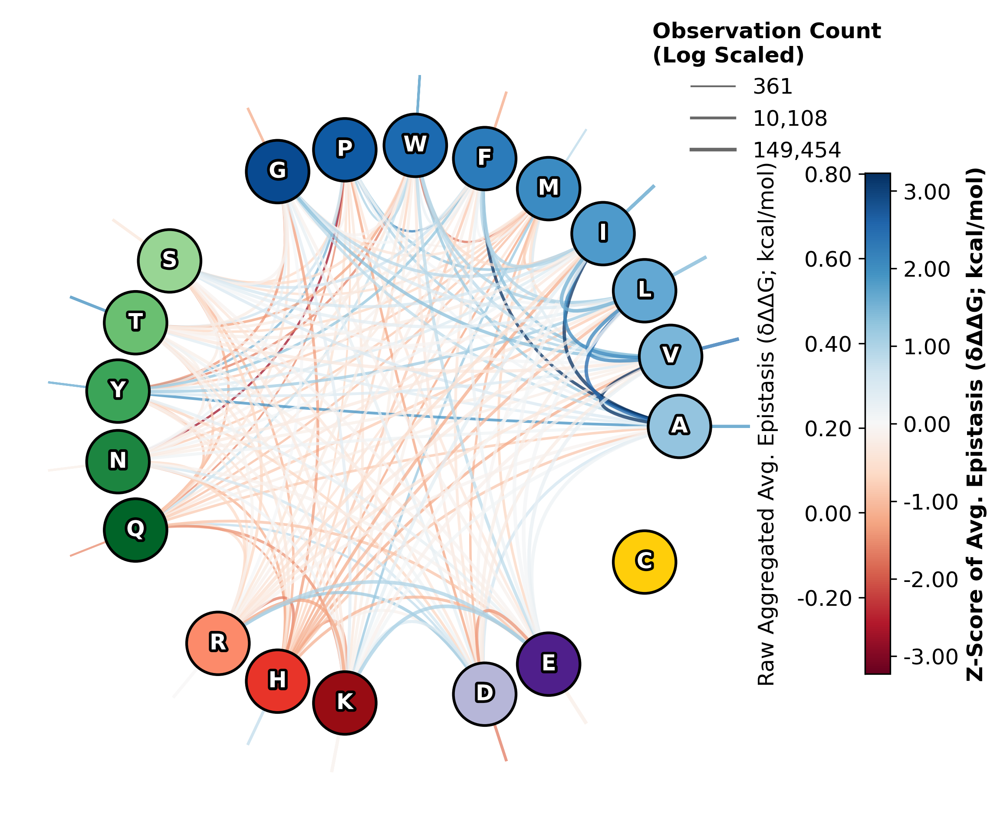

In [ ]:
plot_refined_preference_ring(dfd_zs, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 2400x2400 with 2 Axes>, <Axes: >)

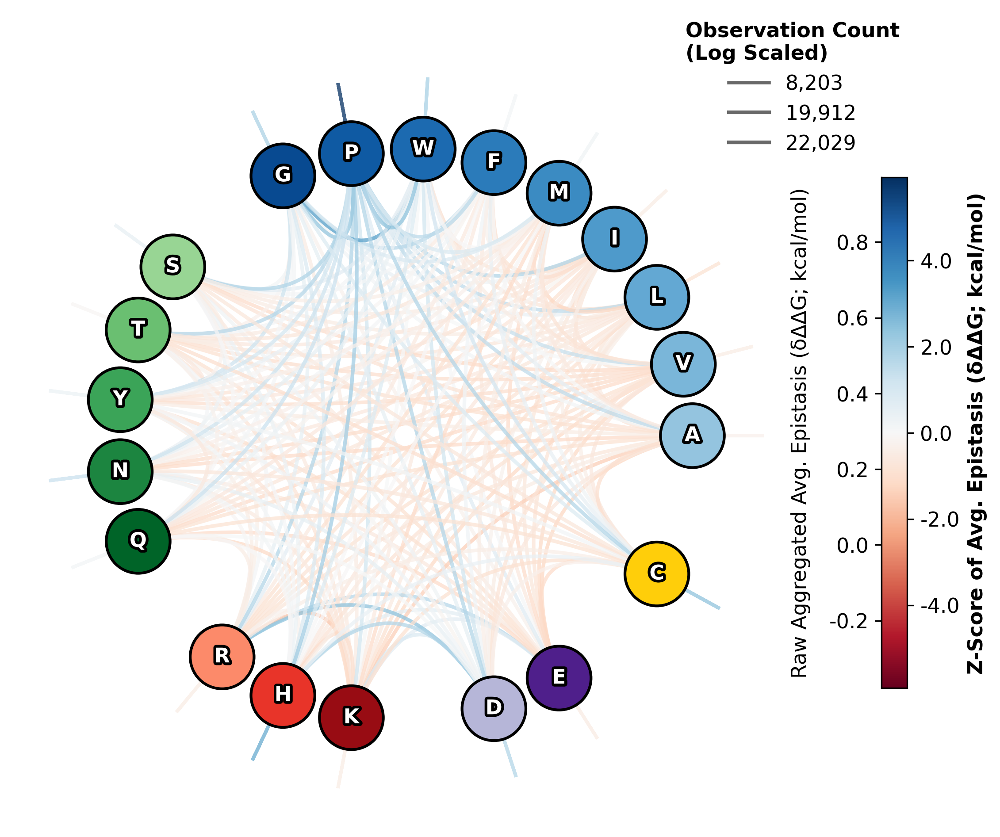

: 

In [ ]:
plot_refined_preference_ring(dfd_zs, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

In [ ]:
dfd.sort_values('Avg. Epistasis (δΔΔG; kcal/mol)').head(50)

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),wt_lora_pred_additive,wt_lora_dddg_pred,...,dist,mut1,mut2,wt1,pos1,mt1,wt2,pos2,mt2,seq_dist
uid,,,,,,,,,,,,,,,,,,,,,
HHH_rd1_0516_A_K22E:K36D,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0516,A,K22E:K36D,0.450861,-2.633500,-1.091320,-2.005934,0.511071,-0.060210,...,4.743188,K22E,K36D,K,22,E,K,36,D,14
HHH_rd1_0516_A_K22E:K36E,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0516,A,K22E:K36E,0.733793,-2.107046,-0.686627,-1.924215,0.794003,-0.060210,...,4.743188,K22E,K36E,K,22,E,K,36,E,14
XX_run1_0455_0002_A_W24R:W41K,/home/sreeves/software/esm-msr/data/tsuboyama/...,XX_run1_0455_0002,A,W24R:W41K,-0.739147,-4.008395,-2.373771,-1.840114,-0.678936,-0.060210,...,4.200790,W24R,W41K,W,24,R,W,41,K,17
HHH_rd1_0493_A_A12E:N17E,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0493,A,A12E:N17E,-0.358869,-3.460829,-1.909849,-1.791355,-0.298659,-0.060210,...,3.514410,A12E,N17E,A,12,E,N,17,E,5
HHH_rd1_0516_A_K22F:K36D,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0516,A,K22F:K36D,0.972629,-0.904950,0.033840,-1.767756,1.032840,-0.060210,...,4.743188,K22F,K36D,K,22,F,K,36,D,14
XX_run1_0455_0002_A_W24R:W41R,/home/sreeves/software/esm-msr/data/tsuboyama/...,XX_run1_0455_0002,A,W24R:W41R,-0.604982,-3.730557,-2.167770,-1.751493,-0.544772,-0.060210,...,4.200790,W24R,W41R,W,24,R,W,41,R,17
HHH_rd1_0473_A_R22F:K36D,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0473,A,R22F:K36D,1.044809,-1.301335,-0.128263,-1.726226,1.105019,-0.060210,...,4.035986,R22F,K36D,R,22,F,K,36,D,14
HHH_rd1_0473_A_R22I:K36D,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0473,A,R22I:K36D,1.008739,-1.010139,-0.000700,-1.712264,1.068950,-0.060210,...,4.035986,R22I,K36D,R,22,I,K,36,D,14
GG_run1_1390_0006_A_K29L:L35D,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run1_1390_0006,A,K29L:L35D,0.776039,-3.317380,-1.270670,-1.710477,0.836250,-0.060210,...,4.220368,K29L,L35D,K,29,L,L,35,D,6


In [ ]:
dfd.sort_values('Avg. Epistasis (δΔΔG; kcal/mol)', ascending=False).head(50)

,pdb_file,code,chain,mut_type,wt_lora_pred,mt_lora_pred,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),wt_lora_pred_additive,wt_lora_dddg_pred,...,dist,mut1,mut2,wt1,pos1,mt1,wt2,pos2,mt2,seq_dist
uid,,,,,,,,,,,,,,,,,,,,,
1UFM_A_L32G:A43F,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,L32G:A43F,-4.660496,1.444251,-1.608122,3.669322,-4.600285,-0.060210,...,4.475166,L32G,A43F,L,32,G,A,43,F,11
1UFM_A_L32G:A43Y,/home/sreeves/software/esm-msr/data/tsuboyama/...,1UFM,A,L32G:A43Y,-5.016464,0.618852,-2.198806,3.403187,-4.956253,-0.060211,...,4.475166,L32G,A43Y,L,32,G,A,43,Y,11
GG_run5_1147_0004_A_L28G:A33W,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run5_1147_0004,A,L28G:A33W,-3.916841,1.120949,-1.397946,3.109375,-3.856631,-0.060210,...,4.568269,L28G,A33W,L,28,G,A,33,W,5
GG_run1_1390_0006_A_G16I:V17E,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run1_1390_0006,A,G16I:V17E,-3.784122,1.616909,-1.083607,3.043049,-3.723912,-0.060210,...,3.463560,G16I,V17E,G,16,I,V,17,E,1
GG_run1_1390_0006_A_G16V:V17E,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run1_1390_0006,A,G16V:V17E,-3.855416,1.503632,-1.175892,3.033701,-3.795205,-0.060210,...,3.463560,G16V,V17E,G,16,V,V,17,E,1
GG_run1_1390_0006_A_G16I:V17D,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run1_1390_0006,A,G16I:V17D,-3.692146,1.953797,-0.869175,3.012395,-3.631936,-0.060210,...,3.463560,G16I,V17D,G,16,I,V,17,D,1
GG_run5_1147_0004_A_A17R:V22D,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run5_1147_0004,A,A17R:V22D,-4.727303,-0.571466,-2.649384,3.009847,-4.667093,-0.060210,...,4.963694,A17R,V22D,A,17,R,V,22,D,5
GG_run1_1390_0006_A_G16I:V17N,/home/sreeves/software/esm-msr/data/tsuboyama/...,GG_run1_1390_0006,A,G16I:V17N,-3.606193,1.684642,-0.960776,3.000691,-3.545982,-0.060211,...,3.463560,G16I,V17N,G,16,I,V,17,N,1
HHH_rd1_0142_A_I16G:A21F,/home/sreeves/software/esm-msr/data/tsuboyama/...,HHH_rd1_0142,A,I16G:A21F,-4.127231,1.471561,-1.327835,2.985782,-4.067020,-0.060211,...,5.738926,I16G,A21F,I,16,G,A,21,F,5


In [ ]:
from esm_msr import utils

ds = preprocessing.MegaScaleDatasetPreprocessor(
    data_file='/home/sareeves/software/esm-msr/data/tsuboyama/Tsuboyama2023_Dataset2_Dataset3_20230416.csv', 
    af_model_folder='/home/sareeves/software/esm-msr/data/tsuboyama/AlphaFold_model_PDBs'
)

print(f"Creating training splits at {split_file}...")
_ = ds.create_training_splits(str(split_file), -1)

data_scaffold = ds.split_dfs['test']

df_true = pd.concat(ds.split_dfs, ignore_index=True)
df_true['uid'] = df_true['code'] + '_' + df_true['chain'] + '_' + df_true['mut_type']
df_true = df_true.set_index('uid')
df_true = utils.sum_individual_mutation_scores(df_true, 'ddG_ML', new_score_column='ddG_additive_ML')
df_true['dddG_ML'] = df_true['ddG_ML'] - df_true['ddG_additive_ML']
df_true = df_true.loc[~df_true['dddG_ML'].isna()]
df_true = df_true.loc[df_true['mut_type'].str.contains(':')]
df_true = df_true.rename(columns={'dddG_ML': 'Avg. Epistasis (δΔΔG; kcal/mol)', 'ddG_ML': 'Avg. Stabilization (ΔΔG; kcal/mol)'})
df_true

2026-05-20 16:23:46,462 - INFO - Loaded raw data: 776298 entries from /home/sareeves/software/esm-msr/data/tsuboyama/Tsuboyama2023_Dataset2_Dataset3_20230416.csv
2026-05-20 16:23:50,842 - INFO - Reduced to: 542229 entries after basic filtering
2026-05-20 16:23:51,658 - INFO - Using split file /home/sareeves/software/esm-msr/data/hyperopt_splits.pkl.


Creating training splits at /home/sareeves/software/esm-msr/data/hyperopt_splits.pkl...


Creating test datasets: 100%|██████████| 34/34 [00:00<00:00, 58.44it/s]


Scaffold train : 127 unique structures:
['1AOY', '1F0M', '1K1V', '1PSE', '1PV0', '1QKH', '1QP2', '1TG0', '1URF', '1V1C', '1WCL', '1YP5', '2BTT', '2D1U', '2EXD', '2JN4', '2JTV', '2K1B', '2K28', '2K52_L42A', '2K52_F21S', '2K9D', '2KCM', '2KFV', '2KRS_W42A', '2KRS_Y53S', '2KRU', '2KT8_V15A', '2KT8_G54S', '2KVS', '2KVT', '2KYB_K55A', '2KYB_G2S', '2L09', '2L33', '2L6Q', '2LC2', '2LGW', '2LQK', '2LVN', '2LYP_V26S', '2LYP_P41A', '2LYQ', '2LYR', '2M0Y', '2M2J', '2M2L', '2M7O_I21A', '2M8E', '2MCH', '2MCK', '2MI6', '2MKX_L11A', '2MKX_N29S', '2MXD', '2MYX', '2N88', '2O2W', '2OCH', '2WNM', '3L1X', '3V1A', '3ZGK', '4C26', '4G3O', '5GU9_V60D', '5GU9_L66K', '5JRT', '5KPH', '5OAO', '5UP5', '6ACV', '6EWS', '6EWU', '6IWS', '6OBK', '6YSE', '7JJK', 'EEHEE_rd3_0130', 'EEHEE_rd3_0146', 'EEHEE_rd3_0602', 'EEHEE_rd3_0657', 'EEHEE_rd3_0809', 'EEHEE_rd3_1049', 'EEHEE_rd3_1367', 'EEHEE_rd3_1498', 'EEHEE_rd3_1587', 'EEHEE_rd3_1810', 'EEHEE_rd3_1818', 'EEHEE_rd4_0003', 'EEHEE_rd4_0005', 'EEHEE_rd4_0308', 'EEHEE_rd

,aa_seq,mut_type,WT_name,mut_structure,code_wt,code,chain,Avg. Stabilization (ΔΔG; kcal/mol),pdb_file,ddG_additive_ML,Avg. Epistasis (δΔΔG; kcal/mol)
uid,,,,,,,,,,,
1F0M_A_Y17A:H50A,SFNTVDEWLEAIKMGQAKESFANAGFTSFDVVSQMMMEDILRVGVT...,Y17A:H50A,1F0M.pdb,NaN,1F0M,1F0M,A,-3.506980,/home/sareeves/software/esm-msr/data/tsuboyama...,-4.693731,1.186751
1F0M_A_Y17A:H50C,SFNTVDEWLEAIKMGQAKESFANAGFTSFDVVSQMMMEDILRVGVT...,Y17A:H50C,1F0M.pdb,NaN,1F0M,1F0M,A,-2.559387,/home/sareeves/software/esm-msr/data/tsuboyama...,-5.643774,3.084387
1F0M_A_Y17A:H50D,SFNTVDEWLEAIKMGQAKESFANAGFTSFDVVSQMMMEDILRVGVT...,Y17A:H50D,1F0M.pdb,NaN,1F0M,1F0M,A,-3.072914,/home/sareeves/software/esm-msr/data/tsuboyama...,-3.348159,0.275245
1F0M_A_Y17A:H50E,SFNTVDEWLEAIKMGQAKESFANAGFTSFDVVSQMMMEDILRVGVT...,Y17A:H50E,1F0M.pdb,NaN,1F0M,1F0M,A,-3.362437,/home/sareeves/software/esm-msr/data/tsuboyama...,-4.383143,1.020706
1F0M_A_Y17A:H50F,SFNTVDEWLEAIKMGQAKESFANAGFTSFDVVSQMMMEDILRVGVT...,Y17A:H50F,1F0M.pdb,NaN,1F0M,1F0M,A,-2.945752,/home/sareeves/software/esm-msr/data/tsuboyama...,-5.588416,2.642664
...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_A_R10Y:E36S,SEEKKKAKEYLERLGASSELARELLDRANGNAEKASRLLRKLL,R10Y:E36S,HHH_rd1_0949.pdb,NaN,HHH_rd1_0949,HHH_rd1_0949,A,-0.293973,/home/sareeves/software/esm-msr/data/tsuboyama...,-1.240620,0.946647
HHH_rd1_0949_A_R10Y:E36T,SEEKKKAKEYLERLGASSELARELLDRANGNAEKATRLLRKLL,R10Y:E36T,HHH_rd1_0949.pdb,NaN,HHH_rd1_0949,HHH_rd1_0949,A,-0.381462,/home/sareeves/software/esm-msr/data/tsuboyama...,-0.983655,0.602194
HHH_rd1_0949_A_R10Y:E36V,SEEKKKAKEYLERLGASSELARELLDRANGNAEKAVRLLRKLL,R10Y:E36V,HHH_rd1_0949.pdb,NaN,HHH_rd1_0949,HHH_rd1_0949,A,0.365883,/home/sareeves/software/esm-msr/data/tsuboyama...,-0.178556,0.544439


(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

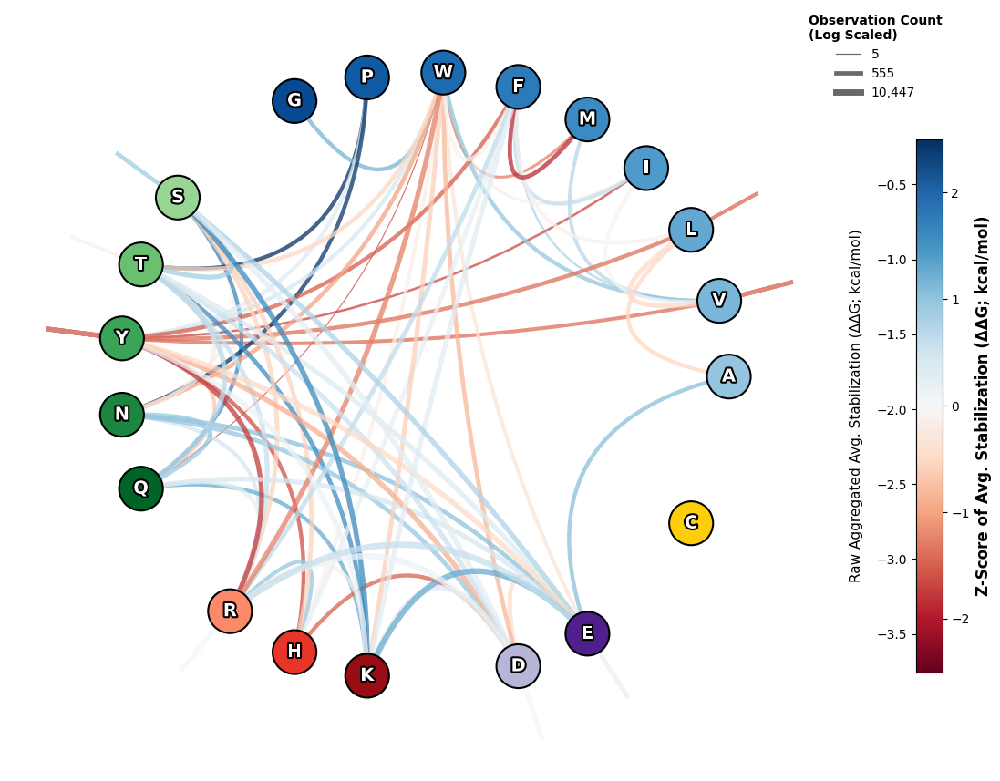

In [ ]:
plot_refined_preference_ring(df_true, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', max_lw=5, normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

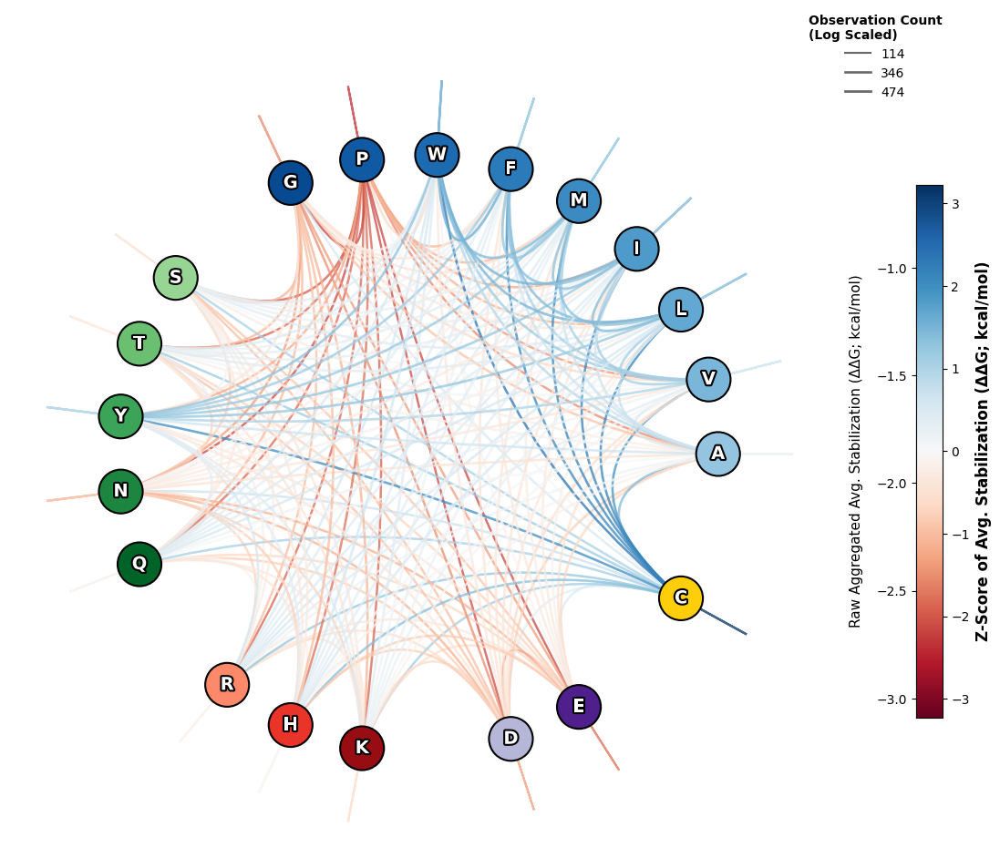

In [ ]:
plot_refined_preference_ring(df_true, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

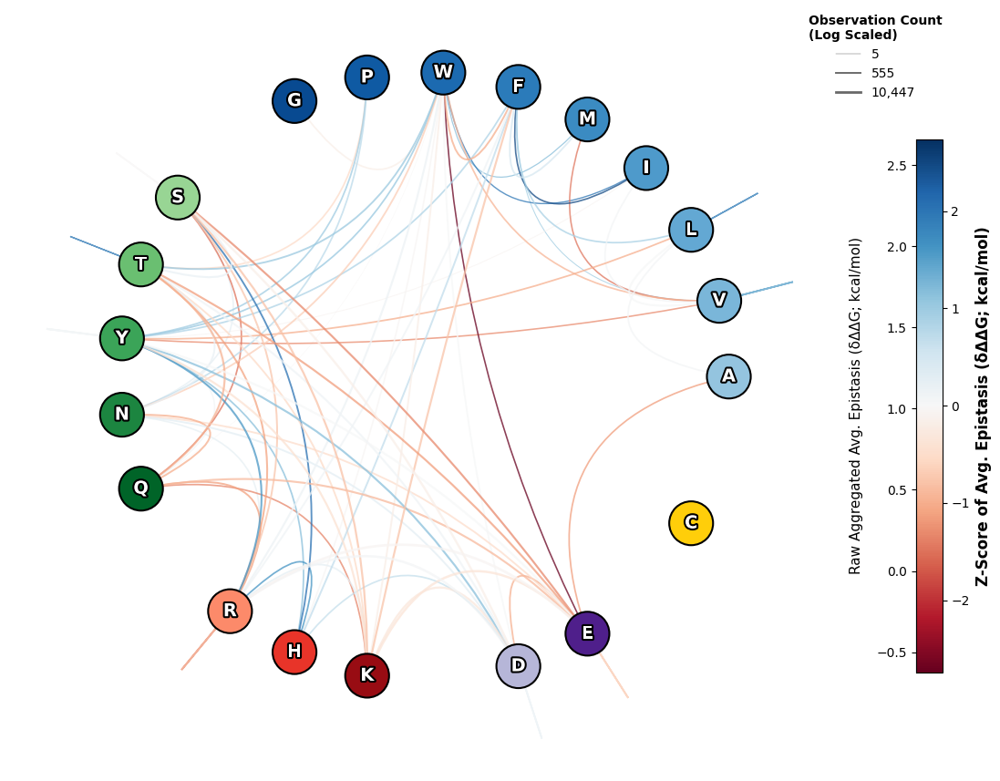

In [ ]:
plot_refined_preference_ring(df_true, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, use_wt=True, scale_lw_by_count=True)

(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

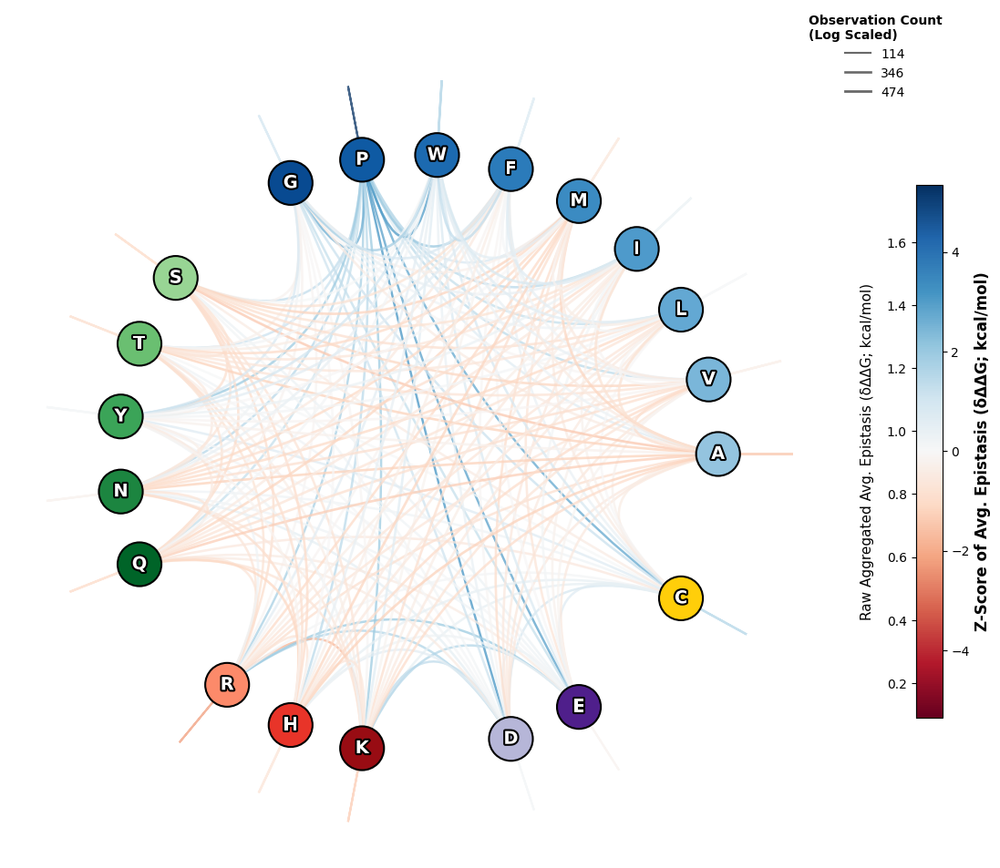

In [ ]:
plot_refined_preference_ring(df_true, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

In [ ]:
df_zs = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/zeroshot_alpha0.0_unmasked_predictions.csv', index_col=0) 
df_zs = df_zs.loc[~df_zs['dddG_ML'].isna()]
df_zs = df_zs.loc[df_zs['mut_type'].str.contains(':')]
df_zs = df_zs.rename(columns={'combined_dddg_pred': 'Avg. Epistasis (δΔΔG; kcal/mol)', 'combined_pred': 'Avg. Stabilization (ΔΔG; kcal/mol)'})


In [ ]:
df_zs

,aa_seq,mut_type,WT_name,mut_structure,code_wt,code,chain,uid,ddG_ML,pdb_file,...,dddG_ML,wt_lora_pred,mt_lora_pred,Avg. Stabilization (ΔΔG; kcal/mol),Avg. Epistasis (δΔΔG; kcal/mol),wt_lora_pred_additive,wt_lora_dddg_pred,mt_lora_pred_additive,mt_lora_dddg_pred,combined_pred_additive
id,,,,,,,,,,,,,,,,,,,,,
1UFM_E14A:E53A,SSGGSSILDRAVIAHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,E14A:E53A,1UFM.pdb,-,1UFM,1UFM,A,1UFM_E14A:E53A,-1.746995,/home/sareeves/software/esm-msr/data/tsuboyama...,...,-0.004082,-2.345369,-1.186415,-1.765892,-0.129607,-2.345369,-5.960464e-08,-0.927200,-0.259215,-1.636285
1UFM_E14A:E53D,SSGGSSILDRAVIAHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,E14A:E53D,1UFM.pdb,-,1UFM,1UFM,A,1UFM_E14A:E53D,-1.524802,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.158829,-1.769692,-0.542415,-1.156054,-0.050104,-1.769692,8.940697e-08,-0.442207,-0.100208,-1.105949
1UFM_E14A:E53F,SSGGSSILDRAVIAHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,E14A:E53F,1UFM.pdb,-,1UFM,1UFM,A,1UFM_E14A:E53F,-2.029420,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.992328,-4.106276,-2.188141,-3.147209,-0.012978,-4.106276,0.000000e+00,-2.162185,-0.025957,-3.134230
1UFM_E14A:E53G,SSGGSSILDRAVIAHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,E14A:E53G,1UFM.pdb,-,1UFM,1UFM,A,1UFM_E14A:E53G,-1.917165,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.351233,-3.452151,-1.793053,-2.622602,-0.126121,-3.452151,1.192093e-07,-1.540810,-0.252242,-2.496481
1UFM_E14A:E53H,SSGGSSILDRAVIAHNLLSASKLYNNITFEELGALLEIPAAKAEKI...,E14A:E53H,1UFM.pdb,-,1UFM,1UFM,A,1UFM_E14A:E53H,-2.040422,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.410570,-3.691190,-2.006237,-2.848714,-0.068687,-3.691190,2.384186e-07,-1.868863,-0.137374,-2.780027
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_R10Y:E36S,SEEKKKAKEYLERLGASSELARELLDRANGNAEKASRLLRKLL,R10Y:E36S,HHH_rd1_0949.pdb,-,HHH_rd1_0949,HHH_rd1_0949,A,HHH_rd1_0949_R10Y:E36S,-0.293973,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.946647,-2.938297,-0.858477,-1.898387,0.426094,-2.938297,-1.192093e-07,-1.710665,0.852188,-2.324481
HHH_rd1_0949_R10Y:E36T,SEEKKKAKEYLERLGASSELARELLDRANGNAEKATRLLRKLL,R10Y:E36T,HHH_rd1_0949.pdb,-,HHH_rd1_0949,HHH_rd1_0949,A,HHH_rd1_0949_R10Y:E36T,-0.381462,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.602194,-2.886528,-0.989600,-1.938064,0.231028,-2.886528,0.000000e+00,-1.451657,0.462057,-2.169092
HHH_rd1_0949_R10Y:E36V,SEEKKKAKEYLERLGASSELARELLDRANGNAEKAVRLLRKLL,R10Y:E36V,HHH_rd1_0949.pdb,-,HHH_rd1_0949,HHH_rd1_0949,A,HHH_rd1_0949_R10Y:E36V,0.365883,/home/sareeves/software/esm-msr/data/tsuboyama...,...,0.544439,-2.181356,-0.606506,-1.393931,0.338372,-2.181356,-1.192093e-07,-1.283250,0.676744,-1.732303


(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

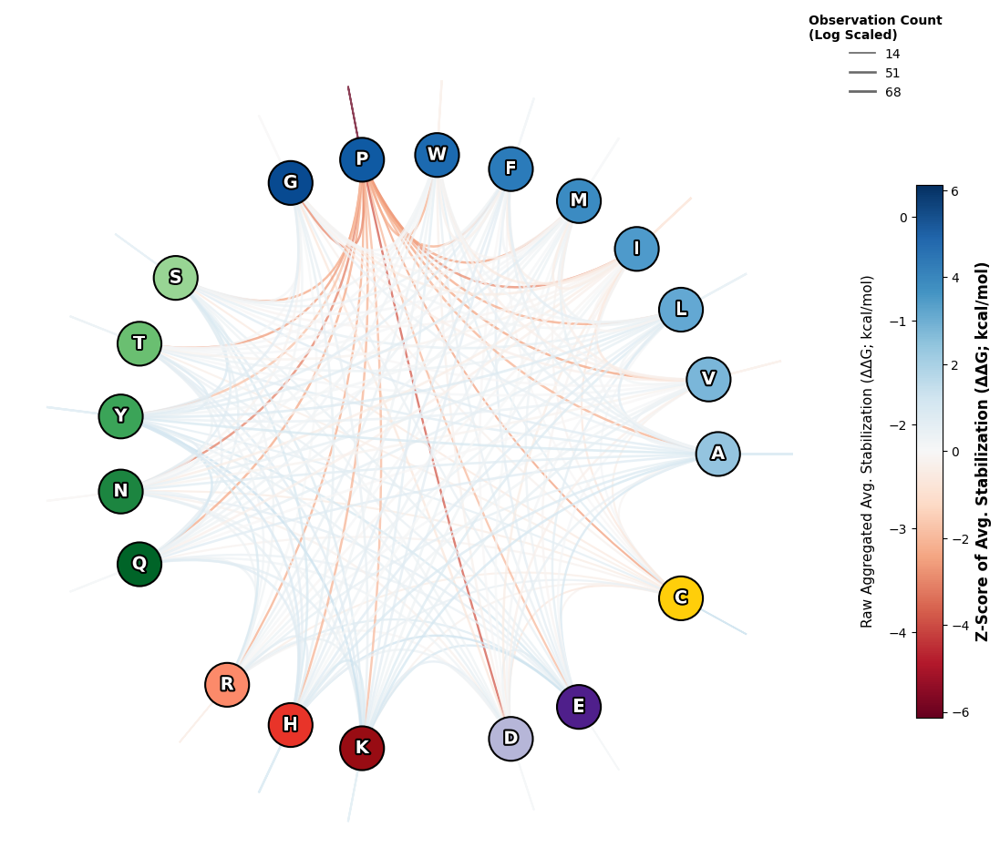

In [ ]:
plot_refined_preference_ring(df_zs, score_col='Avg. Stabilization (ΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

(<Figure size 1200x1200 with 2 Axes>, <Axes: >)

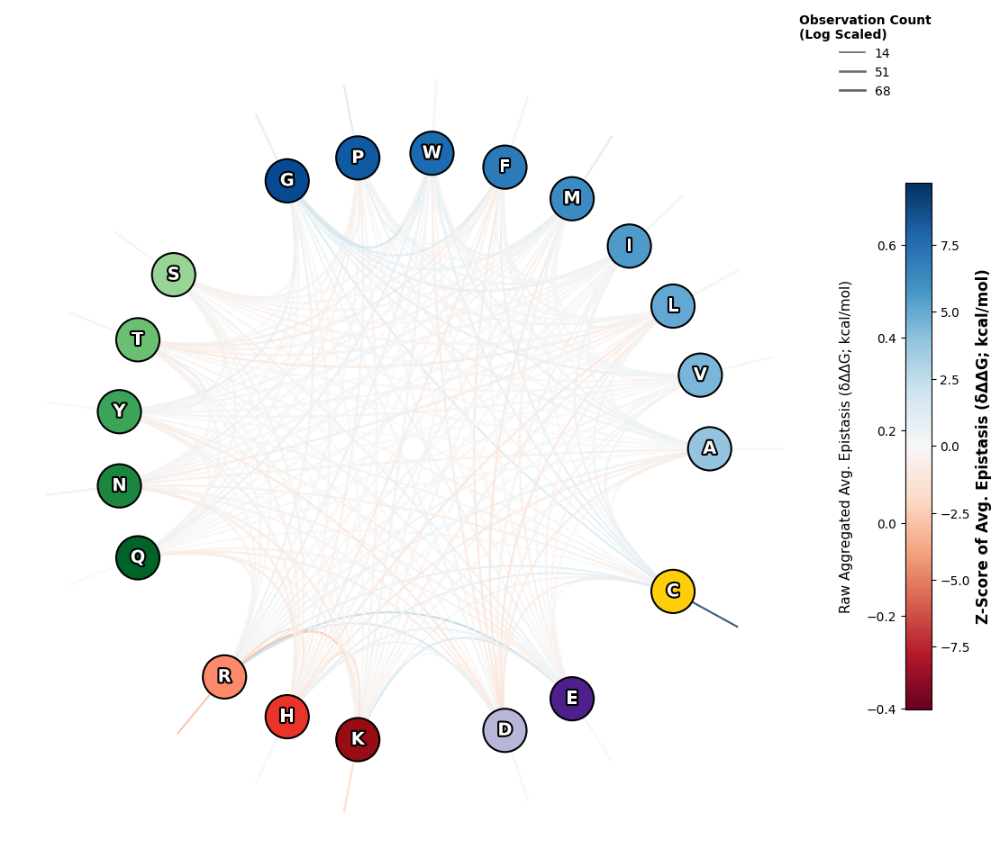

In [ ]:
plot_refined_preference_ring(df_zs, score_col='Avg. Epistasis (δΔΔG; kcal/mol)', center_zero=True, scale_type='dipolar', normalize=True, seq_dist_threshold=1, scale_lw_by_count=True)

In [ ]:
import matplotlib.ticker as ticker


dfd['dddg_abs'] = dfd['Avg. Epistasis (δΔΔG; kcal/mol)'].apply(np.abs)
dfd['dddg_raw'] = dfd['Avg. Epistasis (δΔΔG; kcal/mol)']

# Retaining your original hanging lines
#dfd.plot.scatter(x='dist', y='dddg_abs', alpha=0.02)
#dfd['seq_dist'] = np.abs(dfd['i'] - dfd['j'])

# Prevent silent failures if the dataframe is missing required inputs
if 'Avg. Epistasis (δΔΔG; kcal/mol)' not in dfd.columns or 'dist' not in dfd.columns:
    raise AssertionError("Required columns 'Avg. Epistasis (δΔΔG; kcal/mol)' or 'dist' are missing from dfd.")

# --- NEW: Sequence Distance Filtering ---
MIN_SEQ_DIST = 2  # Threshold: 4 means we only keep pairs separated by at least 4 residues (i.e. i and i+4)

# Safely extract i and j if they don't explicitly exist
if 'i' not in dfd.columns or 'j' not in dfd.columns:
    if 'mut_type' in dfd.columns:
        def extract_positions(mut_str):
            try:
                muts = str(mut_str).split(':')
                if len(muts) == 2:
                    pos1 = int(re.search(r'\d+', muts[0]).group())
                    pos2 = int(re.search(r'\d+', muts[1]).group())
                    return pd.Series([pos1, pos2])
            except Exception:
                pass
            return pd.Series([np.nan, np.nan])
        
        dfd[['i', 'j']] = dfd['mut_type'].apply(extract_positions)
    else:
        raise AssertionError("Columns 'i' and 'j' are missing, and 'mut_type' is not available to extract sequence positions. Cannot compute sequence distance.")

if dfd['i'].isna().any() or dfd['j'].isna().any():
    print("Warning: Some rows contain NaN for sequence positions 'i' or 'j'. These will be dropped during filtering.")

# Vectorized sequence distance computation
dfd['seq_dist'] = np.abs(dfd['i'] - dfd['j'])

# Filter the dataframe and create a strict copy to avoid SettingWithCopyWarnings downstream
initial_len = len(dfd)
dfd = dfd[dfd['seq_dist'] >= MIN_SEQ_DIST].copy()
filtered_len = len(dfd)
print(f"Filtered {initial_len - filtered_len} rows with sequence distance < {MIN_SEQ_DIST}.")
# ----------------------------------------

# Vectorized absolute value computation (replacing the slow .apply)
dfd['dddg_abs'] = np.abs(dfd['Avg. Epistasis (δΔΔG; kcal/mol)'])
dfd['dddg_raw'] = dfd['Avg. Epistasis (δΔΔG; kcal/mol)']

# --- NEW: Check for valid log-scale inputs ---
if (dfd['dist'] <= 0).any():
    raise AssertionError("Values <= 0 found in dfd['dist']. Logarithmic x-scale requires strictly positive distances.")

fig, axes = plt.subplots(1, 1, figsize=(16, 6))

# 1. Scatter Plot with Density (using Hexbin)
# Note: xscale='log' handles the bin boundaries mathematically. 
# gridsize is passed as a tuple (x_bins, y_bins) so you can independently tune resolution.
hb = axes.hexbin(
    dfd['dist'], 
    dfd['dddg_raw'], 
    gridsize=(100, 60),  # Increased y-resolution slightly to match the detailed x-axis
    cmap='inferno', 
    mincnt=1, 
    bins='log',          # Keeps color scale logarithmic
    xscale='log'         # Converts spatial binning on x-axis to log scale
)

axes.axhline(0, color='white', linestyle='--') # Zero-line to clearly demarcate clashes vs synergistic rescue

# Check for potential visual failure due to dense tick labels
max_dist = dfd['dist'].max()
if max_dist > 50:
    print(f"Warning: max distance is {max_dist:.1f}. Forcing labels on all log-scale minor ticks will likely cause severe text overlapping.")

axes.set_xlabel("Distance (Angstroms) [Log Scale]")
axes.set_ylabel("Epistasis (δΔΔG; kcal/mol)")
axes.set_title(f"Interaction vs Distance (Density)\n(Seq Dist >= {MIN_SEQ_DIST})")

# 1. Create a clean formatter that drops unnecessary decimal points
clean_formatter = ticker.FormatStrFormatter('%g')

# 2. Apply the consistent formatter to both major and minor ticks
axes.xaxis.set_major_formatter(clean_formatter)
axes.xaxis.set_minor_formatter(clean_formatter)

# 3. Force matplotlib to draw labels for both major and minor ticks
axes.tick_params(axis='x', which='both', labelbottom=True)

# 4. (Removed the rotation line completely)
# Optional: explicitly set a comfortable font size for the dense labels
plt.setp(axes.get_xticklabels(which='both'), fontsize=10)

cb = fig.colorbar(hb, ax=axes)
cb.set_label('Log10(Count)')

plt.tight_layout()
plt.show()

Filtered 4640294 rows with sequence distance < 2.


ValueError: Invalid vmin or vmax

Error in callback <function _draw_all_if_interactive at 0x710e68220b80> (for post_execute), with arguments args (),kwargs {}:


ValueError: Invalid vmin or vmax

ValueError: Invalid vmin or vmax

<Figure size 1600x600 with 2 Axes>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors
import re

def plot_directed_single_mutations(df, score_col, mut_col='mut_type', 
                                   normalize=False, scale_type='dipolar',
                                   center_zero=True, bezier_tension=0.5,
                                   drop_synonymous=True,
                                   figsize=(12, 12), max_lw=8.0, 
                                   edge_cmap=None):
    """
    Creates a clustered directed circular graph for single mutation preferences.
    Arrows indicate the conversion from Wild-Type to Mutant.
    
    Args:
        drop_synonymous (bool): If True, drops mutations where WT == Mut (e.g., A12A).
    """
    
    # 1. Validation Checks
    assert isinstance(df, pd.DataFrame), "Input df must be a pandas DataFrame."
    assert mut_col in df.columns, f"Mutation column '{mut_col}' not found."
    assert score_col in df.columns, f"Score column '{score_col}' not found."
    assert scale_type in ['dipolar', 'unipolar'], "scale_type must be 'dipolar' or 'unipolar'."
    if df.empty:
        raise ValueError("The provided DataFrame is empty.")
        
    if edge_cmap is None:
        edge_cmap = 'RdYlBu' if scale_type == 'dipolar' else 'Blues'
    
    # 2. Strict Parsing for Single Mutations
    pattern = re.compile(r'^([A-Z])(\d+)([A-Z])$')
    parsed_directed_pairs = []
    valid_indices = []
    
    for idx, val in df[mut_col].items():
        match = pattern.match(val)
        assert match is not None, f"Row {idx} failed parsing. Expected 'X#Y', got '{val}'"
        
        wt, pos, mut = match.groups()
        
        if drop_synonymous and wt == mut:
            continue
            
        valid_indices.append(idx)
        # Store as strict directed tuple: (Source, Target)
        parsed_directed_pairs.append((wt, mut))
        
    df_temp = df.loc[valid_indices].copy()
    if df_temp.empty:
        raise ValueError("No data remaining after applying synonymous filtering.")
        
    df_temp['directed_pair'] = parsed_directed_pairs
    
    # 3. Directed Aggregation
    agg_df = df_temp.groupby('directed_pair')[score_col].sum().reset_index()
    
    # 4. Optional Normalization
    mean_score = agg_df[score_col].mean()
    std_score = agg_df[score_col].std()
    
    if normalize:
        assert std_score > 0, "Standard deviation is 0; cannot normalize identical scores."
        agg_df['plot_score'] = (agg_df[score_col] - mean_score) / std_score
    else:
        agg_df['plot_score'] = agg_df[score_col]
        
    # 5. Strict Linear Colormap Normalization Math
    v_max = agg_df['plot_score'].max()
    v_min = agg_df['plot_score'].min()
    
    if scale_type == 'dipolar' and center_zero:
        abs_max = max(abs(v_min), abs(v_max))
        if abs_max == 0: 
            abs_max = 1.0
        norm = plt.Normalize(vmin=-abs_max, vmax=abs_max)
        agg_df['magnitude'] = agg_df['plot_score'].abs()
    else:
        norm = plt.Normalize(vmin=v_min, vmax=v_max)
        if scale_type == 'unipolar':
            agg_df['magnitude'] = agg_df['plot_score'] - v_min
        else:
            agg_df['magnitude'] = agg_df['plot_score'].abs()

    # 6. Thickness and Z-Order Sorting
    max_mag = agg_df['magnitude'].max()
    assert max_mag > 0, "Maximum calculated magnitude is 0; cannot scale line widths."
    
    agg_df['lw'] = ((agg_df['magnitude'] / max_mag) ** 1.5) * max_lw
    agg_df = agg_df.sort_values(by='magnitude', ascending=True)
    
    # 7. Define Clusters and Calculate Angular Positions
    categories = {
        'Hydrophobic': (['A', 'V', 'L', 'I', 'M', 'F', 'W', 'P', 'G'], plt.cm.Blues),
        'Polar':       (['S', 'T', 'Y', 'N', 'Q'], plt.cm.Greens), 
        'Positive':    (['R', 'H', 'K'], plt.cm.Reds),
        'Negative':    (['D', 'E'], plt.cm.Purples),
        'Special':     (['C'], plt.cm.Wistia) 
    }
    
    total_aas = 20
    num_clusters = len(categories)
    gap_fraction = 0.04 
    total_gap_space = 2 * np.pi * (gap_fraction * num_clusters)
    space_per_aa = (2 * np.pi - total_gap_space) / total_aas
    
    node_positions, node_angles, node_colors = {}, {}, {}
    ordered_aas = []
    
    current_angle = 0.0
    for cat, (aas, cmap) in categories.items():
        colors = cmap(np.linspace(0.4, 0.9, len(aas)))
        for aa, color in zip(aas, colors):
            node_positions[aa] = (np.cos(current_angle), np.sin(current_angle))
            node_angles[aa] = current_angle
            node_colors[aa] = color
            ordered_aas.append(aa)
            current_angle += space_per_aa
        current_angle += (2 * np.pi * gap_fraction)
        
    # 8. Plotting
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect('equal')
    ax.axis('off')
    
    cmap_edges = plt.get_cmap(edge_cmap)
    
    # Draw Edges (Arrows)
    for _, row in agg_df.iterrows():
        wt, mut = row['directed_pair']
        p1 = node_positions[wt]
        p2 = node_positions[mut]
        edge_color = cmap_edges(norm(row['plot_score']))
        
        if wt == mut:
            # Fallback for self-loops if drop_synonymous is False
            loop_control = (p1[0] * 1.5, p1[1] * 1.5)
            path_data = [
                (mpath.Path.MOVETO, p1),
                (mpath.Path.CURVE3, loop_control),
                (mpath.Path.CURVE3, p1)
            ]
        else:
            theta1 = node_angles[wt]
            theta2 = node_angles[mut]
            
            delta_theta = abs(theta1 - theta2)
            if delta_theta > np.pi:
                delta_theta = 2 * np.pi - delta_theta
                
            v_x = np.cos(theta1) + np.cos(theta2)
            v_y = np.sin(theta1) + np.sin(theta2)
            
            r_ctrl_base = max(0.0, 1.0 - (delta_theta / np.pi))
            r_ctrl = r_ctrl_base * bezier_tension
            
            norm_v = np.hypot(v_x, v_y)
            if norm_v == 0:
                ctrl_pt = (0, 0)
            else:
                ctrl_pt = ((v_x / norm_v) * r_ctrl, (v_y / norm_v) * r_ctrl)
                
            path_data = [
                (mpath.Path.MOVETO, p1),
                (mpath.Path.CURVE3, ctrl_pt), 
                (mpath.Path.CURVE3, p2)
            ]
            
        codes, verts = zip(*path_data)
        path = mpath.Path(verts, codes)
        
        # Use FancyArrowPatch to add directionality to the custom path
        arrow = mpatches.FancyArrowPatch(
            path=path,
            arrowstyle='-|>',
            mutation_scale=12 + (row['lw'] * 2.5), # Scale arrowhead with line thickness
            facecolor=edge_color,
            edgecolor=edge_color,
            linewidth=row['lw'],
            alpha=0.75,
            shrinkA=18, shrinkB=18, # Pull arrow back slightly from node centers
            zorder=1
        )
        ax.add_patch(arrow)

    # Draw Nodes
    x_nodes = [node_positions[aa][0] for aa in ordered_aas]
    y_nodes = [node_positions[aa][1] for aa in ordered_aas]
    c_nodes = [node_colors[aa] for aa in ordered_aas]
    
    ax.scatter(x_nodes, y_nodes, s=1200, c=c_nodes, edgecolor='black', linewidth=1.5, zorder=2)
    
    # Label Nodes (Centered with Stroke Path Effect)
    for aa in ordered_aas:
        x, y = node_positions[aa]
        ax.text(x, y, aa, fontsize=14, fontweight='bold', color='white',
                ha='center', va='center', zorder=3,
                path_effects=[pe.withStroke(linewidth=3, foreground='black')])

    # Add Primary Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap_edges, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, aspect=20)
    
    score_label = "Z-Score of Score" if normalize else "Aggregated Score"
    cbar.set_label(score_label, fontsize=12, fontweight='bold')

    # Add Secondary Axis to Colorbar for Raw Scores if Normalized
    if normalize:
        def z_to_raw(z):
            return z * std_score + mean_score
            
        def raw_to_z(raw):
            return (raw - mean_score) / std_score
            
        secax = cbar.ax.secondary_yaxis('left', functions=(z_to_raw, raw_to_z))
        secax.set_ylabel("Raw Aggregated Score", fontsize=11, labelpad=10)

    title_scale = "Diverging" if scale_type == 'dipolar' else "Sequential"
    plt.title(f"Directed Single Mutation Preferences ({title_scale})", 
              fontsize=18, pad=20, fontweight='bold')
    plt.tight_layout()
    
    return fig, ax